# Thermoacoustic Phenomena in a Heat Exchanger

One notebook that combines the whole project:
- **Python:** physics model, 3D diagrams, 3D graphs, 3D charts, comparison tables
- **Machine learning:** scikit-learn classifiers compared on stable vs unstable points
- **Deep learning:** PyTorch MLP surrogate for the growth rate
- **C++:** the `solver_cpp.cpp` sweep is compiled and run from this notebook
- **JavaScript / TypeScript:** an interactive Plotly 3D surface, with the TypeScript source in `dashboard.ts`

Run the notebook from the project root so relative paths resolve.

This is a toy model for teaching and exploration, not a validated design tool.

## 0. Setup

In [1]:
import os, json, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from IPython.display import HTML, display

PROJECT = os.getcwd()
rng = np.random.default_rng(42)

c = 343.0      # speed of sound (m/s)
L = 1.0        # duct length (m)
ZETA = 0.05    # acoustic damping (1/s)

def mode_freq(n):
    return n * c / (2 * L)

def growth_rate(f, tau, Q=1.0, zeta=ZETA):
    # Toy Rayleigh-type model: unstable when sigma > 0
    return Q * np.cos(2 * np.pi * f * tau) - zeta

print('Mode frequencies (Hz):', [round(mode_freq(n), 1) for n in range(1, 5)])

Mode frequencies (Hz): [171.5, 343.0, 514.5, 686.0]


In [2]:
# NumPy MLP fallback (used when PyTorch is not installed)
import numpy as np

def add_phase_features(A):
    """Input columns are (f, tau, Q). Adds cos and sin of the acoustic phase 2*pi*f*tau.
    The phase is the physical quantity that sets the growth rate, so giving it to the network
    as an input is a physics-informed feature. Without it, a short NumPy MLP does not learn the cosine."""
    ph = 2 * np.pi * A[:, 0] * A[:, 1]
    return np.column_stack([A, np.cos(ph), np.sin(ph)])

def np_mlp_fit(X, y, Xv=None, yv=None, hidden=(64, 64), epochs=2000, lr=1e-3, seed=0, patience=None):
    """Pure-NumPy MLP (tanh hidden layers, Adam, full batch). Used when PyTorch is unavailable."""
    rng = np.random.default_rng(seed)
    mu, sd = X.mean(0), X.std(0) + 1e-12
    ym, ys = y.mean(), y.std() + 1e-12
    Xs = (X - mu) / sd
    ts = (y - ym) / ys
    sizes = [X.shape[1], *hidden, 1]
    W = [rng.normal(0, np.sqrt(2 / a), (a, b)) for a, b in zip(sizes[:-1], sizes[1:])]
    B = [np.zeros(b) for b in sizes[1:]]
    params = W + B
    m = [np.zeros_like(p) for p in params]
    v = [np.zeros_like(p) for p in params]

    def forward(Xin):
        acts, h = [Xin], Xin
        for i, (w, b) in enumerate(zip(W, B)):
            z = h @ w + b
            h = np.tanh(z) if i < len(W) - 1 else z
            acts.append(h)
        return acts

    def predict(Xnew):
        return forward((Xnew - mu) / sd)[-1].ravel() * ys + ym

    best_loss, best_params, bad = np.inf, None, 0
    tr_hist, va_hist = [], []
    for ep in range(1, epochs + 1):
        acts = forward(Xs)
        err = acts[-1].ravel() - ts
        tr_hist.append(float(np.mean(err ** 2)))
        delta = (2 * err / len(ts)).reshape(-1, 1)
        gW, gB = [None] * len(W), [None] * len(B)
        for i in reversed(range(len(W))):
            gW[i] = acts[i].T @ delta
            gB[i] = delta.sum(0)
            if i > 0:
                delta = (delta @ W[i].T) * (1 - acts[i] ** 2)
        for j, (p, g) in enumerate(zip(params, gW + gB)):
            m[j] = 0.9 * m[j] + 0.1 * g
            v[j] = 0.999 * v[j] + 0.001 * g * g
            p -= lr * (m[j] / (1 - 0.9 ** ep)) / (np.sqrt(v[j] / (1 - 0.999 ** ep)) + 1e-8)
        if Xv is not None:
            vl = float(np.mean(((predict(Xv) - yv) / ys) ** 2))
            va_hist.append(vl)
            if vl < best_loss - 1e-9:
                best_loss, best_params, bad = vl, [p.copy() for p in params], 0
            else:
                bad += 1
            if patience and bad >= patience:
                break
    if best_params is not None:
        for p, bp in zip(params, best_params):
            p[...] = bp
    return predict, np.array(tr_hist), np.array(va_hist), (best_loss if Xv is not None else None)

## 1. Physics: growth-rate surface and mode shapes (3D diagrams)

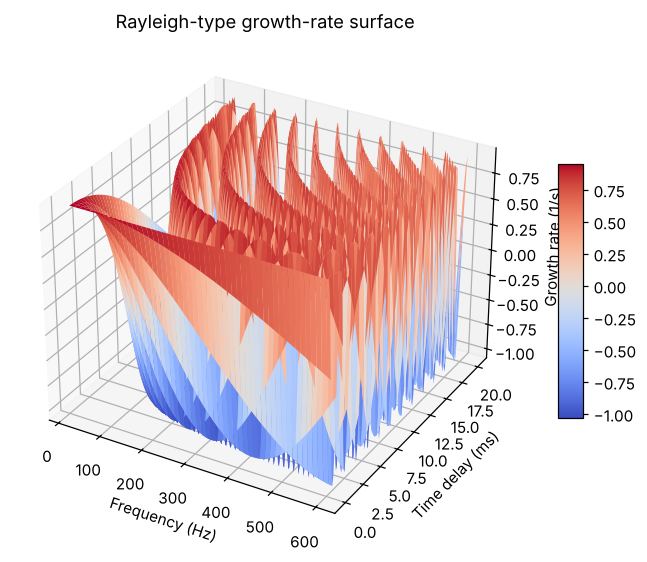

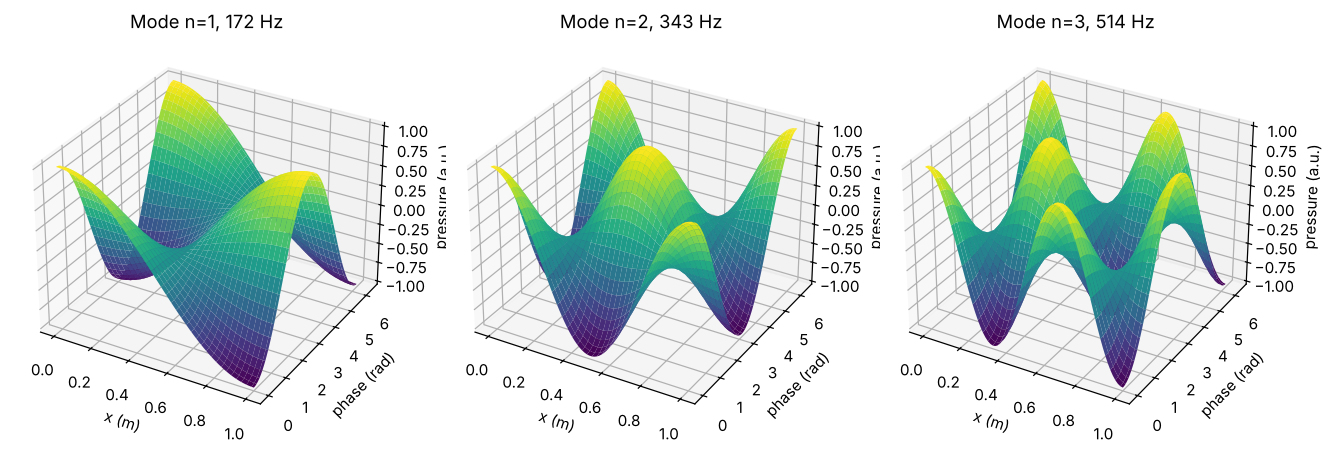

In [3]:
f = np.linspace(20, 600, 150)
tau = np.linspace(0.0, 0.02, 150)
F, T = np.meshgrid(f, tau)
S = growth_rate(F, T)

fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(F, T * 1000, S, cmap='coolwarm', linewidth=0)
ax.set_xlabel('Frequency (Hz)'); ax.set_ylabel('Time delay (ms)'); ax.set_zlabel('Growth rate (1/s)')
ax.set_title('Rayleigh-type growth-rate surface')
fig.colorbar(surf, shrink=0.5, aspect=10)
plt.show()

x = np.linspace(0, L, 80)
phase = np.linspace(0, 2 * np.pi, 80)
X, P_ph = np.meshgrid(x, phase)
fig = plt.figure(figsize=(12, 5))
for i, n in enumerate([1, 2, 3]):
    p = np.cos(n * np.pi * X / L) * np.cos(P_ph)
    ax = fig.add_subplot(1, 3, i + 1, projection='3d')
    ax.plot_surface(X, P_ph, p, cmap='viridis', linewidth=0)
    ax.set_xlabel('x (m)'); ax.set_ylabel('phase (rad)'); ax.set_zlabel('pressure (a.u.)')
    ax.set_title(f'Mode n={n}, {mode_freq(n):.0f} Hz')
plt.tight_layout(); plt.show()

## 2. 3D graph: amplitude growth for stable and unstable cases

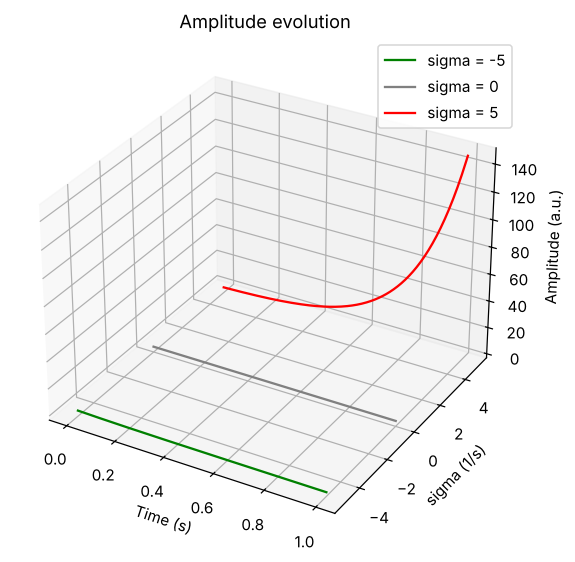

In [4]:
t = np.linspace(0, 1, 200)
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
for sigma, color in [(-5, 'green'), (0, 'gray'), (5, 'red')]:
    ax.plot(t, np.full_like(t, sigma), np.exp(sigma * t), color=color, label=f'sigma = {sigma}')
ax.set_xlabel('Time (s)'); ax.set_ylabel('sigma (1/s)'); ax.set_zlabel('Amplitude (a.u.)')
ax.set_title('Amplitude evolution'); ax.legend()
plt.show()

## 3. C++ solver: compile, run, and visualise its output

The solver in `solver_cpp.cpp` is compiled with `g++` and its CSV is loaded here. If `g++` is missing, this section is skipped.

C++ sweep written to /mnt/user-data/outputs/thermoacoustic_heat_exchanger/sweep_cpp.csv


,mode,freq_Hz,Q,tau_s,sigma
0,1,171.5,0.5,0.000000,0.450000
1,1,171.5,0.5,0.000101,0.447071
2,1,171.5,0.5,0.000201,0.438317
3,1,171.5,0.5,0.000302,0.423842
4,1,171.5,0.5,0.000402,0.403815


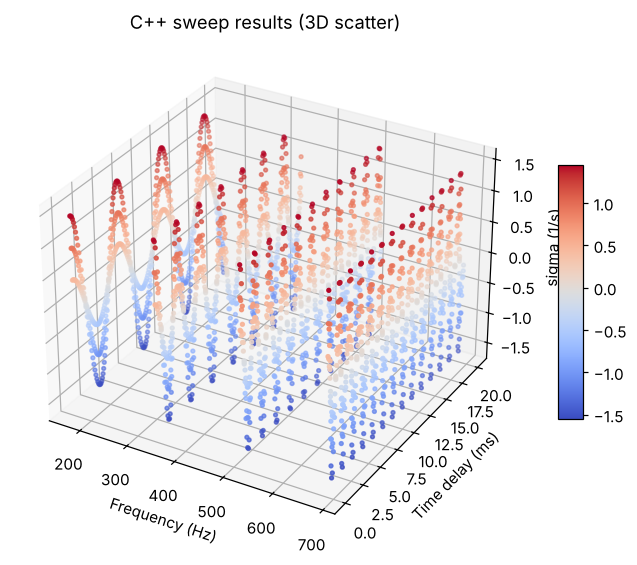

In [5]:
src = os.path.join(PROJECT, 'solver_cpp.cpp')
import tempfile
exe = os.path.join(tempfile.mkdtemp(), 'solver_cpp')   # build outside the project folder
csv_path = os.path.join(PROJECT, 'sweep_cpp.csv')

cpp_ok = False
if not os.path.exists(src):
    print('solver_cpp.cpp not found. Run the notebook from the project root.')
else:
    res = subprocess.run(['g++', '-O2', '-std=c++17', src, '-o', exe], capture_output=True, text=True)
    if res.returncode != 0:
        print('Compile failed:\n', res.stderr)
    else:
        with open(csv_path, 'w') as fh:
            subprocess.run([exe], stdout=fh, check=True)
        cpp_ok = True
        print('C++ sweep written to', csv_path)

if cpp_ok:
    sweep = pd.read_csv(csv_path)
    display(sweep.head())

    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection='3d')
    sc = ax.scatter(sweep['freq_Hz'], sweep['tau_s'] * 1000, sweep['sigma'],
                    c=sweep['sigma'], cmap='coolwarm', s=6)
    ax.set_xlabel('Frequency (Hz)'); ax.set_ylabel('Time delay (ms)'); ax.set_zlabel('sigma (1/s)')
    ax.set_title('C++ sweep results (3D scatter)')
    fig.colorbar(sc, shrink=0.5, aspect=10)
    plt.show()

## 4. 3D comparison table and 3D bar chart

Peak growth rate per mode and heat-release level:


,freq_Hz,max sigma (Q=0.5),max sigma (Q=1.0),max sigma (Q=1.5)
mode,,,,
1,171.5,0.45,0.95,1.45
2,343.0,0.45,0.95,1.45
3,514.5,0.45,0.95,1.45
4,686.0,0.45,0.95,1.45


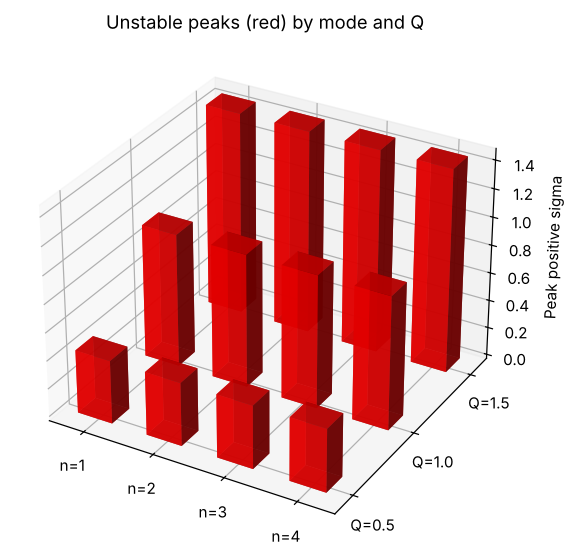

In [6]:
if cpp_ok:
    table = (sweep.groupby(['mode', 'Q'])['sigma'].max()
                  .unstack('Q')
                  .round(3))
    table.insert(0, 'freq_Hz', [round(mode_freq(n), 1) for n in table.index])
    table.columns = ['freq_Hz'] + [f'max sigma (Q={q})' for q in table.columns[1:]]
    print('Peak growth rate per mode and heat-release level:')
    display(table)

    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection='3d')
    Qs = sorted(sweep['Q'].unique())
    modes = sorted(sweep['mode'].unique())
    for xi, n in enumerate(modes):
        for yi, Q in enumerate(Qs):
            z = table.loc[n, table.columns[1 + yi]]
            ax.bar3d(xi, yi, 0, 0.5, 0.25, max(z, 0), color='red' if z > 0 else 'green', alpha=0.8)
    ax.set_xticks(np.arange(len(modes)) + 0.25); ax.set_xticklabels([f'n={n}' for n in modes])
    ax.set_yticks(np.arange(len(Qs)) + 0.12); ax.set_yticklabels([f'Q={q}' for q in Qs])
    ax.set_zlabel('Peak positive sigma')
    ax.set_title('Unstable peaks (red) by mode and Q')
    plt.show()

## 5. Machine learning: compare classifiers for stable vs unstable points

Model comparison:


,test_accuracy
RandomForest,0.6900
GradientBoosting,0.6117
LogisticRegression,0.5417


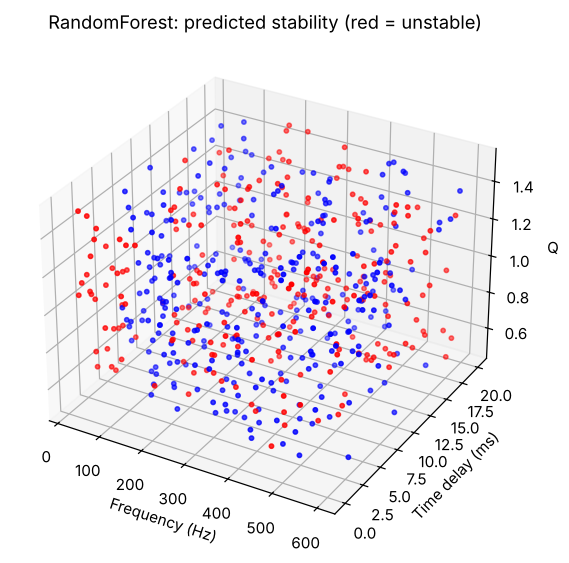

In [7]:
N = 3000
df = pd.DataFrame({
    'f': rng.uniform(20, 600, N),
    'tau': rng.uniform(0.0, 0.02, N),
    'Q': rng.uniform(0.5, 1.5, N),
})
df['sigma'] = growth_rate(df['f'], df['tau'], df['Q'])
df['unstable'] = (df['sigma'] > 0).astype(int)

X = df[['f', 'tau', 'Q']]
y = df['unstable']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    'LogisticRegression': LogisticRegression(max_iter=1000),
    'RandomForest': RandomForestClassifier(n_estimators=200, random_state=42),
    'GradientBoosting': GradientBoostingClassifier(random_state=42),
}
scores, preds = {}, {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    preds[name] = m.predict(X_te)
    scores[name] = accuracy_score(y_te, preds[name])

score_table = pd.DataFrame({'test_accuracy': scores}).sort_values('test_accuracy', ascending=False)
print('Model comparison:')
display(score_table.round(4))

best = score_table.index[0]
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_te['f'], X_te['tau'] * 1000, X_te['Q'], c=preds[best], cmap='bwr', s=8)
ax.set_xlabel('Frequency (Hz)'); ax.set_ylabel('Time delay (ms)'); ax.set_zlabel('Q')
ax.set_title(f'{best}: predicted stability (red = unstable)')
plt.show()

## 6. Deep learning: MLP surrogate for the growth rate (PyTorch)

PyTorch not available: using the NumPy MLP fallback.


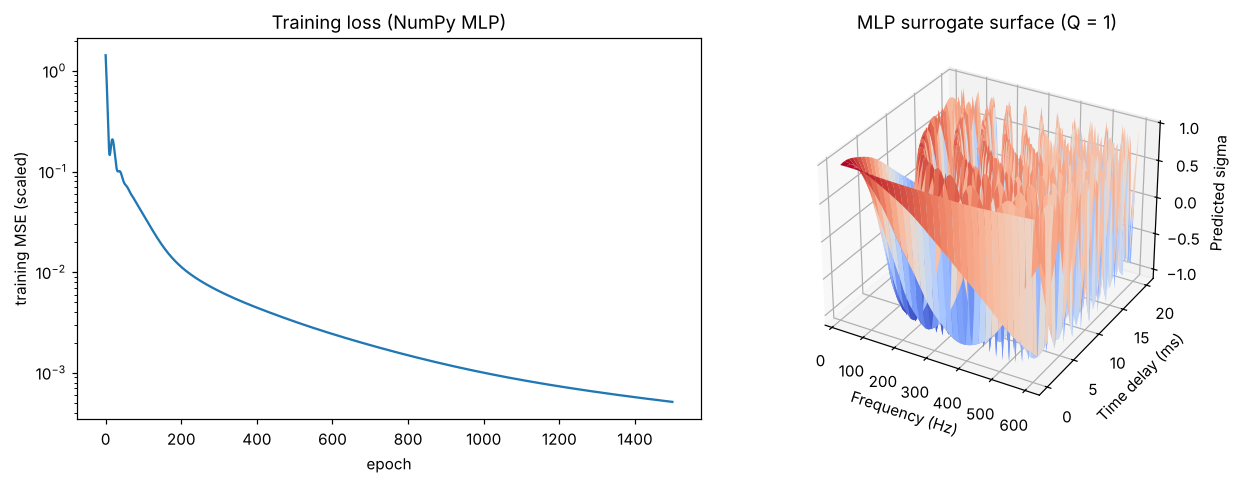

In [8]:
try:
    import torch
    import torch.nn as nn

    torch.manual_seed(0)
    Xt = torch.tensor(X_tr.values, dtype=torch.float32)
    yt = torch.tensor(df.loc[X_tr.index, 'sigma'].values, dtype=torch.float32).unsqueeze(1)
    Xv = torch.tensor(X_te.values, dtype=torch.float32)
    yv = torch.tensor(df.loc[X_te.index, 'sigma'].values, dtype=torch.float32).unsqueeze(1)

    net = nn.Sequential(nn.Linear(3, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    loss_fn = nn.MSELoss()
    history = []
    for epoch in range(400):
        opt.zero_grad()
        loss = loss_fn(net(Xt), yt)
        loss.backward()
        opt.step()
        history.append(loss.item())

    with torch.no_grad():
        val_mse = loss_fn(net(Xv), yv).item()
    print(f'Validation MSE: {val_mse:.5f}')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(history); axes[0].set_yscale('log')
    axes[0].set_xlabel('epoch'); axes[0].set_ylabel('training MSE'); axes[0].set_title('Training loss')
    fg = np.linspace(20, 600, 60); tg = np.linspace(0, 0.02, 60)
    FG, TG = np.meshgrid(fg, tg)
    grid = torch.tensor(np.column_stack([FG.ravel(), TG.ravel(), np.ones(FG.size)]), dtype=torch.float32)
    with torch.no_grad():
        pred_surface = net(grid).numpy().reshape(FG.shape)
    axes[1].remove()
    ax3 = fig.add_subplot(1, 2, 2, projection='3d')
    ax3.plot_surface(FG, TG * 1000, pred_surface, cmap='coolwarm', linewidth=0)
    ax3.set_xlabel('Frequency (Hz)'); ax3.set_ylabel('Time delay (ms)'); ax3.set_zlabel('Predicted sigma')
    ax3.set_title('MLP surrogate surface (Q = 1)')
    plt.tight_layout(); plt.show()
except ImportError:
    print('PyTorch not available: using the NumPy MLP fallback.')
    predict6, hist6, _, _ = np_mlp_fit(add_phase_features(X_tr.values), df.loc[X_tr.index, 'sigma'].values, epochs=1500)
    fg = np.linspace(20, 600, 60); tg = np.linspace(0, 0.02, 60)
    FG, TG = np.meshgrid(fg, tg)
    pred_surface = predict6(add_phase_features(np.column_stack([FG.ravel(), TG.ravel(), np.ones(FG.size)]))).reshape(FG.shape)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(hist6); axes[0].set_yscale('log')
    axes[0].set_xlabel('epoch'); axes[0].set_ylabel('training MSE (scaled)'); axes[0].set_title('Training loss (NumPy MLP)')
    axes[1].remove()
    ax3 = fig.add_subplot(1, 2, 2, projection='3d')
    ax3.plot_surface(FG, TG * 1000, pred_surface, cmap='coolwarm', linewidth=0)
    ax3.set_xlabel('Frequency (Hz)'); ax3.set_ylabel('Time delay (ms)'); ax3.set_zlabel('Predicted sigma')
    ax3.set_title('MLP surrogate surface (Q = 1)')
    plt.tight_layout(); plt.show()

## 7. JavaScript / TypeScript: interactive 3D surface (Plotly)

The same surface as an interactive Plotly chart. The TypeScript dashboard source is in `dashboard.ts`.

In [9]:
f_js = np.linspace(20, 600, 120)
tau_js = np.linspace(0.0, 0.02, 120)
F_js, T_js = np.meshgrid(f_js, tau_js)
S_js = growth_rate(F_js, T_js)

payload = json.dumps({'x': f_js.tolist(), 'y': (tau_js * 1000).tolist(), 'z': S_js.tolist()})
html = """
<div id="plotly3d" style="height:480px"></div>
<script src="https://cdn.plot.ly/plotly-2.27.0.min.js"></script>
<script>
const d = __PAYLOAD__;
Plotly.newPlot("plotly3d", [{type: "surface", x: d.x, y: d.y, z: d.z,
  colorscale: "RdBu", reversescale: true}],
  {title: "Interactive growth-rate surface (Q = 1)", margin: {l: 0, r: 0, t: 40, b: 0},
   scene: {xaxis: {title: "Frequency (Hz)"}, yaxis: {title: "Time delay (ms)"}, zaxis: {title: "sigma (1/s)"}}});
</script>
""".replace('__PAYLOAD__', payload)
display(HTML(html))

## 8. Summary

In [10]:
summary = {
    'Mode frequencies (Hz)': [round(mode_freq(n), 1) for n in range(1, 5)],
    'Best classifier': score_table.index[0],
    'Best test accuracy': round(float(score_table['test_accuracy'].iloc[0]), 4),
    'C++ solver used': cpp_ok,
}
display(pd.Series(summary, name='value').to_frame())

,value
Mode frequencies (Hz),"[171.5, 343.0, 514.5, 686.0]"
Best classifier,RandomForest
Best test accuracy,0.69
C++ solver used,True


## 9. Next steps
- Replace the toy model with a linearised acoustic network or a Helmholtz solver.
- Validate against experimental data from a heat-exchanger test rig.
- Extend the C++ solver with a time-domain integrator.

## 10. Data cleaning

Real sensor data is noisy. This section simulates a pressure-sensor recording with noise, spikes, missing values and duplicate rows, then cleans it step by step and reports the quality before and after.

In [11]:
t_s = np.arange(0, 2.0, 1 / 2000)                      # 2 s at 2 kHz
f_meas = mode_freq(2)                                  # measured mode frequency
clean_signal = 0.8 * np.sin(2 * np.pi * f_meas * t_s)
raw = clean_signal + rng.normal(0, 0.05, t_s.size)     # sensor noise

raw[rng.choice(t_s.size, 40, replace=False)] = 25.0    # spike outliers
raw[rng.choice(t_s.size, 60, replace=False)] = np.nan  # dropped samples

sensor = pd.DataFrame({'time_s': t_s, 'pressure_pa': raw})
sensor = pd.concat([sensor, sensor.iloc[:50]], ignore_index=True)  # duplicate rows
print('Raw shape:', sensor.shape)
sensor.head()

Raw shape: (4050, 2)


,time_s,pressure_pa
0,0.0000,-0.078306
1,0.0005,0.780641
2,0.0010,0.717906
3,0.0015,-0.055255
4,0.0020,-0.727881


In [12]:
# 1) Remove duplicate timestamps and sort
df_c = sensor.drop_duplicates(subset='time_s').sort_values('time_s').reset_index(drop=True)

# 2) Flag outliers with a robust z-score (median and MAD), not mean and std
med = df_c['pressure_pa'].median()
mad = (df_c['pressure_pa'] - med).abs().median()
robust_z = 0.6745 * (df_c['pressure_pa'] - med) / mad
outlier_mask = robust_z.abs() > 3.5
print('Outliers flagged:', int(outlier_mask.sum()))
df_c.loc[outlier_mask, 'pressure_pa'] = np.nan

# 3) Fill missing and flagged samples by time interpolation
df_c['pressure_pa'] = df_c['pressure_pa'].interpolate(method='linear').bfill().ffill()

report = pd.DataFrame({
    'raw': [len(sensor), int(sensor['pressure_pa'].isna().sum()), int(sensor['time_s'].duplicated().sum()),
            round(float(sensor['pressure_pa'].max()), 2)],
    'cleaned': [len(df_c), int(df_c['pressure_pa'].isna().sum()), int(df_c['time_s'].duplicated().sum()),
                round(float(df_c['pressure_pa'].max()), 2)],
}, index=['rows', 'missing values', 'duplicate timestamps', 'max pressure (Pa)'])
display(report)

rmse = np.sqrt(np.mean((df_c['pressure_pa'].values - clean_signal) ** 2))
print(f'RMSE of cleaned signal against the true signal: {rmse:.4f} Pa')

Outliers flagged: 40
RMSE of cleaned signal against the true signal: 0.0706 Pa


,raw,cleaned
rows,4050.0,4000.00
missing values,61.0,0.00
duplicate timestamps,50.0,0.00
max pressure (Pa),25.0,0.95


## 11. Computer visualisation: heatmaps, spectrogram and animation

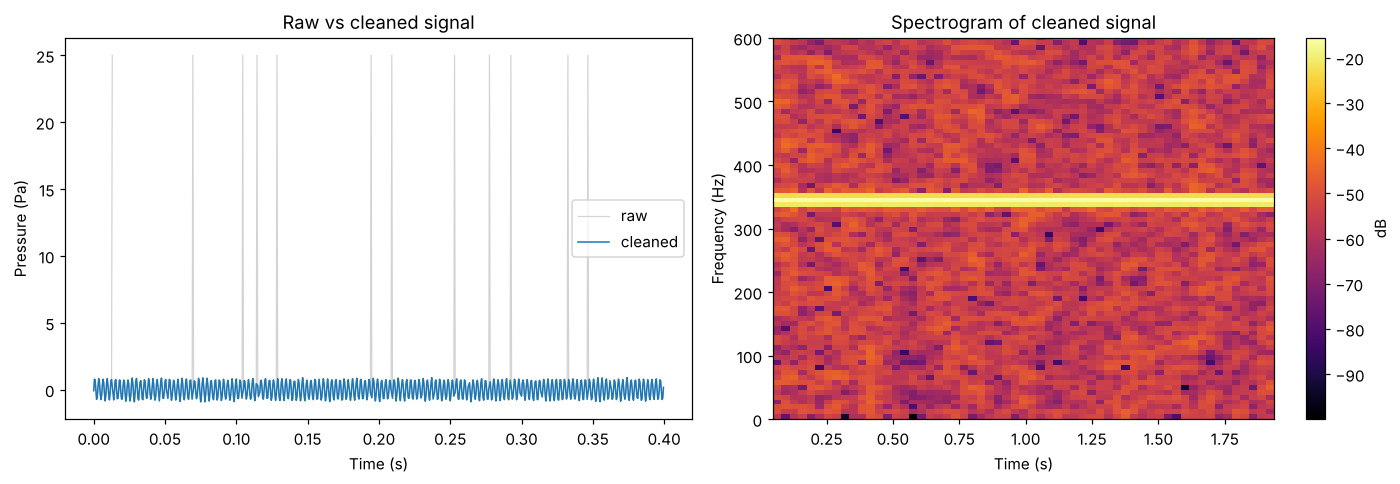

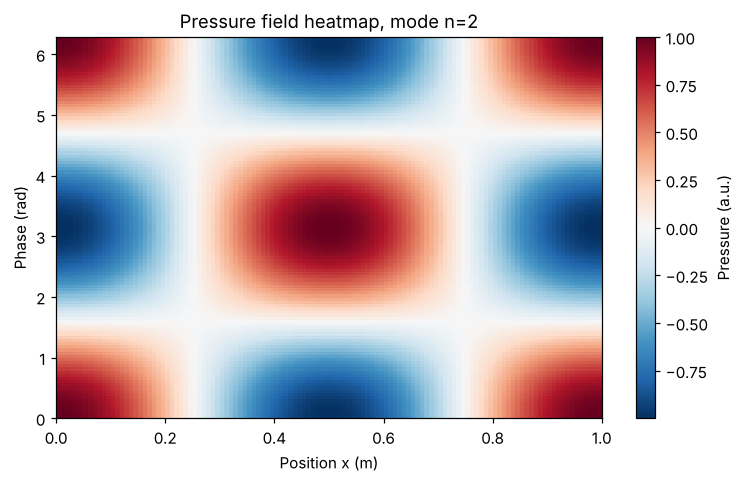

In [13]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(sensor['time_s'][:800], sensor['pressure_pa'][:800], color='lightgray', lw=0.8, label='raw')
axes[0].plot(df_c['time_s'][:800], df_c['pressure_pa'][:800], color='tab:blue', lw=1, label='cleaned')
axes[0].set_xlabel('Time (s)'); axes[0].set_ylabel('Pressure (Pa)')
axes[0].set_title('Raw vs cleaned signal'); axes[0].legend()

Pxx, freqs, bins, im = axes[1].specgram(df_c['pressure_pa'].values, NFFT=256, Fs=2000, noverlap=192, cmap='inferno')
axes[1].set_ylim(0, 600)
axes[1].set_xlabel('Time (s)'); axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Spectrogram of cleaned signal')
fig.colorbar(im, ax=axes[1], label='dB')
plt.tight_layout(); plt.show()

x_hm = np.linspace(0, L, 120)
t_hm = np.linspace(0, 2 * np.pi, 120)
Xh, Th = np.meshgrid(x_hm, t_hm)
field = np.cos(2 * np.pi * Xh / L) * np.cos(Th)
fig, ax = plt.subplots(figsize=(8, 4.5))
hm = ax.imshow(field, extent=[0, L, 0, 2 * np.pi], origin='lower', aspect='auto', cmap='RdBu_r')
ax.set_xlabel('Position x (m)'); ax.set_ylabel('Phase (rad)')
ax.set_title('Pressure field heatmap, mode n=2')
fig.colorbar(hm, ax=ax, label='Pressure (a.u.)')
plt.show()

In [14]:
from matplotlib import animation

xa = np.linspace(0, L, 60)
Xa, Ya = np.meshgrid(xa, np.linspace(0, 2 * np.pi, 60))

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection='3d')

def draw(frame):
    ax.clear()
    phase = 2 * np.pi * frame / 40
    Z = np.cos(2 * np.pi * Xa / L) * np.cos(Ya + phase)
    ax.plot_surface(Xa, Ya, Z, cmap='viridis', linewidth=0)
    ax.set_zlim(-1.1, 1.1)
    ax.set_xlabel('x (m)'); ax.set_ylabel('phase (rad)'); ax.set_zlabel('pressure (a.u.)')
    ax.set_title(f'Mode n=2 animation, frame {frame}')
    return []

anim = animation.FuncAnimation(fig, draw, frames=40, interval=80)
gif_path = os.path.join(PROJECT, 'mode_animation.gif')
anim.save(gif_path, writer=animation.PillowWriter(fps=12))
plt.close(fig)
print('Animation saved to', gif_path)

Animation saved to /mnt/user-data/outputs/thermoacoustic_heat_exchanger/mode_animation.gif


## 12. Pandas: exploratory analysis of the operating-point dataset

Pandas is used here to group, summarise, and pivot the simulated operating points.

In [15]:
df_ops = df.copy()
df_ops['Q_bin'] = pd.cut(df_ops['Q'], bins=[0.5, 0.75, 1.0, 1.25, 1.5], include_lowest=True)
df_ops['tau_bin_ms'] = pd.cut(df_ops['tau'] * 1000, bins=5)

print('Summary statistics:')
display(df_ops[['f', 'tau', 'Q', 'sigma']].describe().round(4))

print('Fraction unstable by heat-release bin:')
display(df_ops.groupby('Q_bin', observed=True)['unstable'].mean().round(3).to_frame('unstable_fraction'))

pivot = df_ops.pivot_table(index='tau_bin_ms', columns='Q_bin', values='unstable', aggfunc='mean', observed=True)
print('Unstable fraction pivot (time delay x heat release):')
display(pivot.round(2))

Summary statistics:
Fraction unstable by heat-release bin:
Unstable fraction pivot (time delay x heat release):


,f,tau,Q,sigma
count,3000.0000,3000.0000,3000.0000,3000.0000
mean,309.7191,0.0098,1.0015,-0.0522
std,168.2849,0.0057,0.2878,0.7385
min,20.3009,0.0000,0.5004,-1.5411
25%,161.8225,0.0049,0.7550,-0.6664
50%,307.6492,0.0097,1.0052,-0.0451
75%,458.5263,0.0147,1.2443,0.5499
max,599.8639,0.0200,1.5000,1.4492


,unstable_fraction
Q_bin,
"(0.499, 0.75]",0.474
"(0.75, 1.0]",0.491
"(1.0, 1.25]",0.480
"(1.25, 1.5]",0.473


Q_bin,"(0.499, 0.75]","(0.75, 1.0]","(1.0, 1.25]","(1.25, 1.5]"
tau_bin_ms,,,,
"(-0.0137, 4.004]",0.48,0.50,0.58,0.52
"(4.004, 8.001]",0.50,0.36,0.40,0.43
"(8.001, 11.999]",0.47,0.53,0.48,0.43
"(11.999, 15.997]",0.48,0.49,0.47,0.48
"(15.997, 19.994]",0.43,0.58,0.48,0.50


## 13. Machine learning: cross-validation, feature importance and tuning

Best RandomForest params: {'max_depth': None, 'n_estimators': 100}
Held-out accuracy of tuned model: 0.6900


,5-fold CV accuracy
RandomForest,0.6570
GradientBoosting,0.5837
LogisticRegression,0.5170


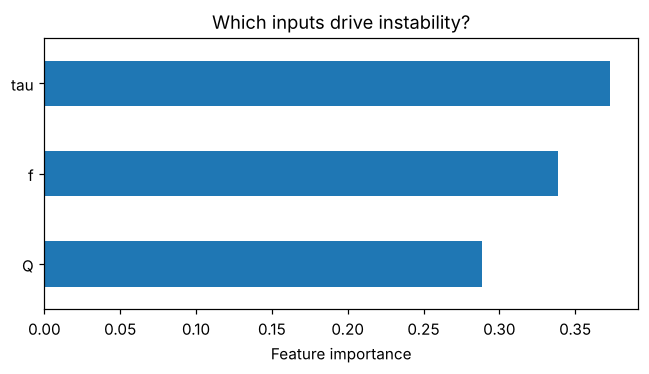

In [16]:
from sklearn.model_selection import cross_val_score, GridSearchCV

cv_rows = {}
for name, m in models.items():
    cv_rows[name] = cross_val_score(m, X, y, cv=5, scoring='accuracy').mean()
cv_table = pd.Series(cv_rows, name='5-fold CV accuracy').sort_values(ascending=False).to_frame()
display(cv_table.round(4))

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid={'n_estimators': [100, 300], 'max_depth': [None, 5, 10]},
    cv=5, scoring='accuracy', n_jobs=-1,
)
grid.fit(X_tr, y_tr)
print('Best RandomForest params:', grid.best_params_)
print(f'Held-out accuracy of tuned model: {grid.score(X_te, y_te):.4f}')

importances = pd.Series(grid.best_estimator_.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(6, 3.5))
importances.plot.barh(ax=ax, color='tab:blue')
ax.set_xlabel('Feature importance'); ax.set_title('Which inputs drive instability?')
plt.tight_layout(); plt.show()

## 14. Deep learning: early stopping, validation split and metrics

PyTorch not available: using the NumPy MLP fallback.
Validation MSE (scaled): 0.00072
Validation MAE: 0.0145
Validation R^2: 0.9993


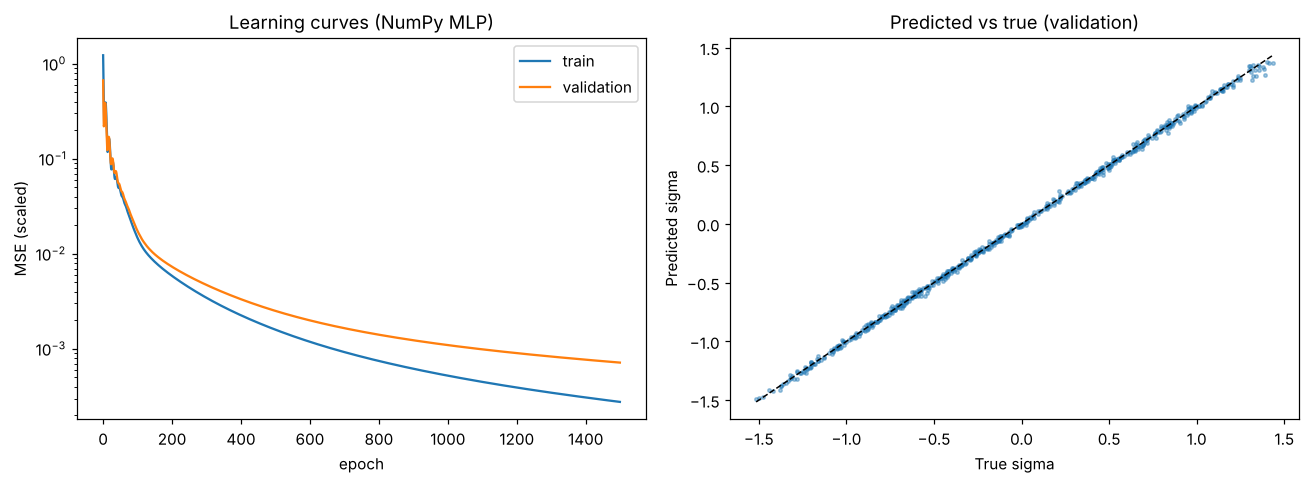

In [17]:
idx = np.arange(len(X))
tr_idx, va_idx = train_test_split(idx, test_size=0.2, random_state=0)

try:
    import torch
    import torch.nn as nn
    from sklearn.metrics import mean_absolute_error, r2_score

    torch.manual_seed(1)
    X_all = torch.tensor(X.values, dtype=torch.float32)
    y_all = torch.tensor(df['sigma'].values, dtype=torch.float32).unsqueeze(1)

    net = nn.Sequential(nn.Linear(3, 128), nn.ReLU(), nn.Dropout(0.1),
                        nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 1))
    opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-5)
    loss_fn = nn.MSELoss()

    best_val, best_state, patience, bad = float('inf'), None, 30, 0
    train_hist, val_hist = [], []
    for epoch in range(500):
        net.train()
        opt.zero_grad()
        tr_loss = loss_fn(net(X_all[tr_idx]), y_all[tr_idx])
        tr_loss.backward()
        opt.step()

        net.eval()
        with torch.no_grad():
            va_loss = loss_fn(net(X_all[va_idx]), y_all[va_idx]).item()
        train_hist.append(tr_loss.item())
        val_hist.append(va_loss)

        if va_loss < best_val - 1e-6:
            best_val, bad = va_loss, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print(f'Early stopping at epoch {epoch}')
                break

    net.load_state_dict(best_state)
    net.eval()
    with torch.no_grad():
        pred = net(X_all[va_idx]).numpy().ravel()
    true = y_all[va_idx].numpy().ravel()
    print(f'Validation MSE: {best_val:.5f}')
    print(f'Validation MAE: {mean_absolute_error(true, pred):.4f}')
    print(f'Validation R^2: {r2_score(true, pred):.4f}')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(train_hist, label='train'); axes[0].plot(val_hist, label='validation')
    axes[0].set_yscale('log'); axes[0].set_xlabel('epoch'); axes[0].set_ylabel('MSE')
    axes[0].set_title('Learning curves'); axes[0].legend()
    axes[1].scatter(true, pred, s=5, alpha=0.4)
    lims = [true.min(), true.max()]
    axes[1].plot(lims, lims, 'k--', lw=1)
    axes[1].set_xlabel('True sigma'); axes[1].set_ylabel('Predicted sigma')
    axes[1].set_title('Predicted vs true (validation)')
    plt.tight_layout(); plt.show()
except ImportError:
    print('PyTorch not available: using the NumPy MLP fallback.')
    from sklearn.metrics import mean_absolute_error, r2_score
    sig = df['sigma'].values
    XF = add_phase_features(X.values)
    predict14, tr14, va14, best14 = np_mlp_fit(XF[tr_idx], sig[tr_idx], XF[va_idx], sig[va_idx],
                                              hidden=(128, 128), epochs=1500, patience=80)
    pred = predict14(XF[va_idx]); true = sig[va_idx]
    print(f'Validation MSE (scaled): {best14:.5f}')
    print(f'Validation MAE: {mean_absolute_error(true, pred):.4f}')
    print(f'Validation R^2: {r2_score(true, pred):.4f}')
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(tr14, label='train'); axes[0].plot(va14, label='validation')
    axes[0].set_yscale('log'); axes[0].set_xlabel('epoch'); axes[0].set_ylabel('MSE (scaled)')
    axes[0].set_title('Learning curves (NumPy MLP)'); axes[0].legend()
    axes[1].scatter(true, pred, s=5, alpha=0.4)
    lims = [true.min(), true.max()]
    axes[1].plot(lims, lims, 'k--', lw=1)
    axes[1].set_xlabel('True sigma'); axes[1].set_ylabel('Predicted sigma')
    axes[1].set_title('Predicted vs true (validation)')
    plt.tight_layout(); plt.show()

## 15. Python project utilities

The the project root folder holds reusable functions. This cell imports them so the notebook and command-line tools share one implementation.

In [18]:
import sys
sys.path.insert(0, PROJECT)
try:
    from thermo_utils import mode_frequency, growth_rate_model
    print('Mode 3 frequency:', mode_frequency(3), 'Hz')
    print('Growth rate at 100 Hz, tau=3 ms, Q=1:', round(growth_rate_model(100, 0.003, 1.0), 4))
except ImportError as e:
    print('Utilities not found:', e)

Mode 3 frequency: 514.5 Hz
Growth rate at 100 Hz, tau=3 ms, Q=1: -0.359


## 16. Mathematical analysis

**Incompressible Navier-Stokes equations** (constant density $\rho$, kinematic viscosity $\nu$):

$$\partial_t \mathbf{u} + (\mathbf{u}\cdot\nabla)\mathbf{u} = -\tfrac{1}{\rho}\nabla p + \nu\nabla^2\mathbf{u}, \qquad \nabla\cdot\mathbf{u} = 0.$$

**Status of the theory.** Existence and smoothness of solutions in 3D is the Clay Millennium Problem and is **unsolved**. What is established: local existence and uniqueness for smooth data, and global regularity in 2D. This notebook therefore does not claim a new theorem. It does three verifiable things:

1. Prove an energy identity for the damped acoustic model (a standard result, checked numerically).
2. Check the exact Taylor-Green vortex, a known solution of the 2D Navier-Stokes equations, by computing its residual.
3. Compare the analytic and numerical stability boundaries of the toy growth-rate model.

Max dE/dt (should be <= 0 up to numerical error): -3.898702499682827e-05
Energy ratio E(4)/E(0) numeric: 0.01741
Analytic envelope exp(-2 zeta t) at t=4: 0.018316


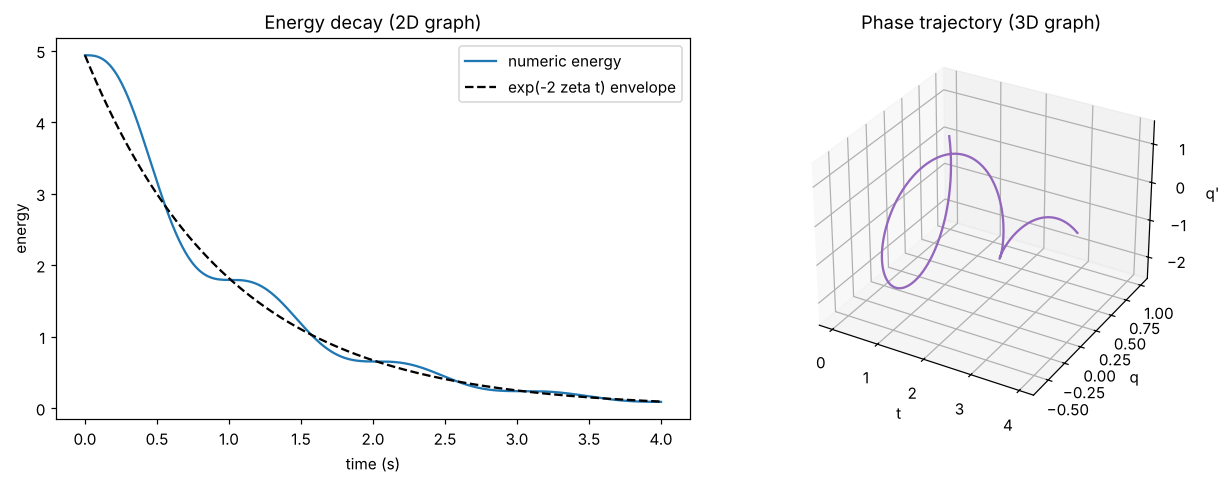

In [19]:
from scipy.integrate import solve_ivp

# Damped acoustic mode: q'' + 2 zeta q' + omega^2 q = 0
# Energy E = 1/2 (q'^2 + omega^2 q^2) satisfies dE/dt = -2 zeta (q')^2 <= 0 (energy identity)
omega = 2 * np.pi * mode_freq(1) / c   # angular frequency in rad/s (scaled model)
zeta_damp = 0.5

def rhs(t, y):
    q, dq = y
    return [dq, -2 * zeta_damp * dq - omega ** 2 * q]

t_eval = np.linspace(0, 4, 800)
sol = solve_ivp(rhs, (0, 4), [1.0, 0.0], t_eval=t_eval, rtol=1e-10, atol=1e-12)
q, dq = sol.y
E = 0.5 * (dq ** 2 + omega ** 2 * q ** 2)

dE_dt = np.gradient(E, t_eval)
print('Max dE/dt (should be <= 0 up to numerical error):', float(dE_dt.max()))
print('Energy ratio E(4)/E(0) numeric:', round(E[-1] / E[0], 6))
print('Analytic envelope exp(-2 zeta t) at t=4:', round(float(np.exp(-2 * zeta_damp * 4)), 6))

fig = plt.figure(figsize=(12, 4.5))
ax1 = fig.add_subplot(121)
ax1.plot(t_eval, E, label='numeric energy')
ax1.plot(t_eval, E[0] * np.exp(-2 * zeta_damp * t_eval), 'k--', label='exp(-2 zeta t) envelope')
ax1.set_xlabel('time (s)'); ax1.set_ylabel('energy'); ax1.set_title('Energy decay (2D graph)'); ax1.legend()

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot(t_eval, q, dq, color='tab:purple')
ax2.set_xlabel('t'); ax2.set_ylabel('q'); ax2.set_zlabel("q'")
ax2.set_title('Phase trajectory (3D graph)')
plt.tight_layout(); plt.show()

In [20]:
# Taylor-Green vortex: exact solution of the 2D incompressible Navier-Stokes equations
nu = 0.05
N = 64
xs = np.linspace(0, 2 * np.pi, N, endpoint=False)
ys = np.linspace(0, 2 * np.pi, N, endpoint=False)
X2, Y2 = np.meshgrid(xs, ys, indexing='ij')
h = xs[1] - xs[0]

def tg_fields(t):
    F = np.exp(-2 * nu * t)
    u = np.cos(X2) * np.sin(Y2) * F
    v = -np.sin(X2) * np.cos(Y2) * F
    p = -0.25 * (np.cos(2 * X2) + np.cos(2 * Y2)) * F ** 2
    return u, v, p

def ns_residual(t):
    # Residual of momentum equations via central finite differences (periodic domain)
    u, v, p = tg_fields(t)
    F = np.exp(-2 * nu * t)
    dt_u = -2 * nu * u
    dt_v = -2 * nu * v
    ddx = lambda f: (np.roll(f, -1, 0) - np.roll(f, 1, 0)) / (2 * h)
    ddy = lambda f: (np.roll(f, -1, 1) - np.roll(f, 1, 1)) / (2 * h)
    lap = lambda f: (np.roll(f, -1, 0) + np.roll(f, 1, 0) + np.roll(f, -1, 1) + np.roll(f, 1, 1) - 4 * f) / h ** 2
    px, py = ddx(p), ddy(p)
    ru = dt_u + u * ddx(u) + v * ddy(u) + px - nu * lap(u)
    rv = dt_v + u * ddx(v) + v * ddy(v) + py - nu * lap(v)
    div = ddx(u) + ddy(v)
    return np.abs(ru).max(), np.abs(rv).max(), np.abs(div).max()

for t in [0.0, 1.0, 3.0]:
    ru, rv, dv = ns_residual(t)
    print(f't={t}: momentum residual max = {max(ru, rv):.2e}, divergence max = {dv:.2e}')

t=0.0: momentum residual max = 2.46e-03, divergence max = 4.66e-15
t=1.0: momentum residual max = 2.02e-03, divergence max = 4.11e-15
t=3.0: momentum residual max = 1.36e-03, divergence max = 3.44e-15


Kinetic energy: max relative error vs exp(-4 nu t): 3.169710637501177e-16


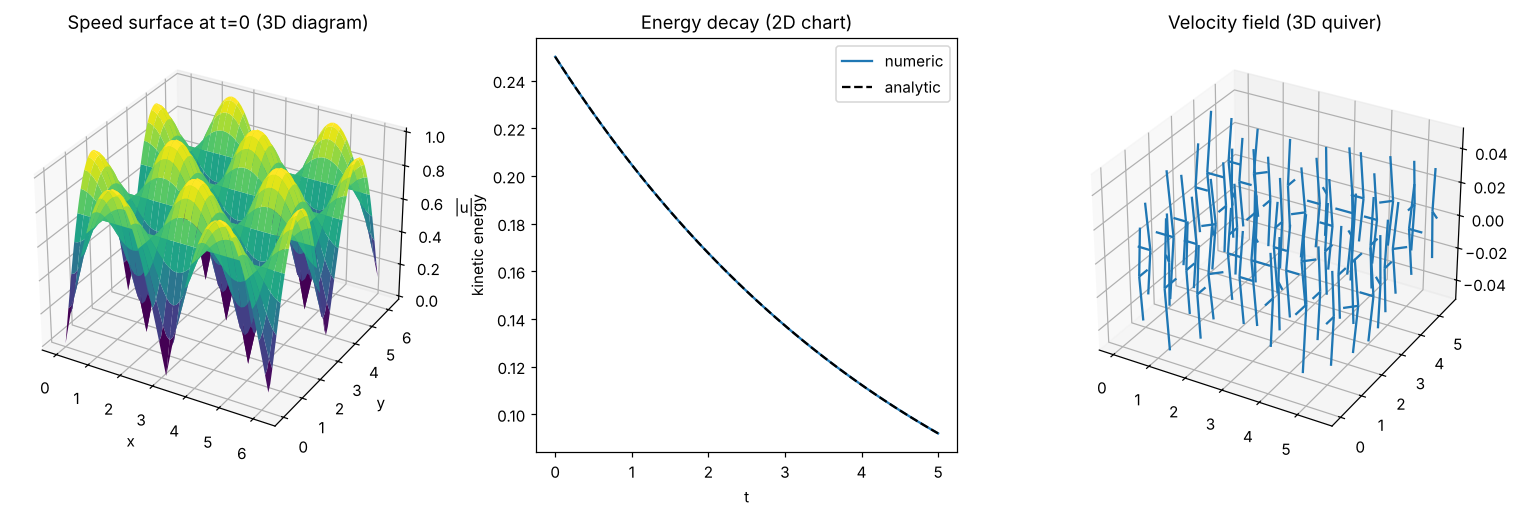

In [21]:
times = np.linspace(0, 5, 60)
kinetic = []
for t in times:
    u, v, _ = tg_fields(t)
    kinetic.append(0.5 * np.mean(u ** 2 + v ** 2))
kinetic = np.array(kinetic)
analytic = kinetic[0] * np.exp(-4 * nu * times)
print('Kinetic energy: max relative error vs exp(-4 nu t):',
      float(np.max(np.abs(kinetic - analytic) / analytic)))

u0, v0, p0 = tg_fields(0.0)
fig = plt.figure(figsize=(14, 4.8))
ax1 = fig.add_subplot(131, projection='3d')
ax1.plot_surface(X2, Y2, np.sqrt(u0 ** 2 + v0 ** 2), cmap='viridis', linewidth=0)
ax1.set_title('Speed surface at t=0 (3D diagram)')
ax1.set_xlabel('x'); ax1.set_ylabel('y'); ax1.set_zlabel('|u|')

ax2 = fig.add_subplot(132)
ax2.plot(times, kinetic, label='numeric')
ax2.plot(times, analytic, 'k--', label='analytic')
ax2.set_xlabel('t'); ax2.set_ylabel('kinetic energy'); ax2.set_title('Energy decay (2D chart)'); ax2.legend()

ax3 = fig.add_subplot(133, projection='3d')
step = 8
ax3.quiver(X2[::step, ::step], Y2[::step, ::step], np.zeros_like(X2[::step, ::step]),
           u0[::step, ::step], v0[::step, ::step], np.zeros_like(u0[::step, ::step]), length=0.5)
ax3.set_title('Velocity field (3D quiver)')
plt.tight_layout(); plt.show()

In [22]:
# Stability analysis of the toy growth-rate model: analytic vs numerical boundary
# sigma(tau) = Q cos(2 pi f tau) - zeta. Unstable region exists iff Q > zeta.
# Analytic maximum over tau is Q - zeta, reached at tau = 0 (mod 1/f).
zeta = ZETA
rows = []
for n in [1, 2, 3, 4]:
    f_n = mode_freq(n)
    for Q in [0.03, 0.05, 0.5, 1.0]:
        tau_grid = np.linspace(0, 1 / f_n, 4000)
        numeric_max = growth_rate(f_n, tau_grid, Q, zeta).max()
        analytic_max = Q - zeta
        rows.append({'mode': n, 'freq_Hz': round(f_n, 1), 'Q': Q,
                     'analytic_max_sigma': round(analytic_max, 4),
                     'numeric_max_sigma': round(float(numeric_max), 4),
                     'unstable_possible': Q > zeta})
stab = pd.DataFrame(rows)
display(stab.style.format(precision=4))
print('Max absolute gap analytic vs numeric:',
      float((stab['analytic_max_sigma'] - stab['numeric_max_sigma']).abs().max()))

Max absolute gap analytic vs numeric: 0.0


,mode,freq_Hz,Q,analytic_max_sigma,numeric_max_sigma,unstable_possible
0,1,171.5000,0.0300,-0.0200,-0.0200,False
1,1,171.5000,0.0500,0.0000,0.0000,False
2,1,171.5000,0.5000,0.4500,0.4500,True
3,1,171.5000,1.0000,0.9500,0.9500,True
4,2,343.0000,0.0300,-0.0200,-0.0200,False
5,2,343.0000,0.0500,0.0000,0.0000,False
6,2,343.0000,0.5000,0.4500,0.4500,True
7,2,343.0000,1.0000,0.9500,0.9500,True
8,3,514.5000,0.0300,-0.0200,-0.0200,False
9,3,514.5000,0.0500,0.0000,0.0000,False


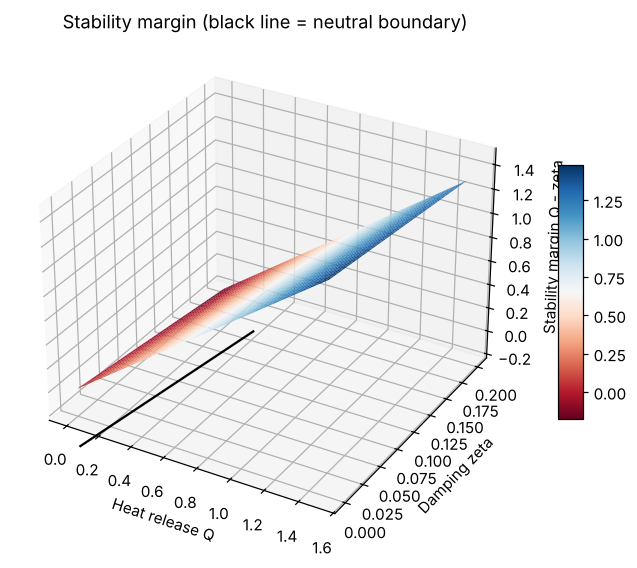

In [23]:
# 3D chart: stability margin Q - zeta across heat-release and damping
Qs3 = np.linspace(0.0, 1.5, 60)
zs3 = np.linspace(0.0, 0.2, 60)
QQ, ZZ = np.meshgrid(Qs3, zs3)
margin = QQ - ZZ
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(QQ, ZZ, margin, cmap='RdBu', linewidth=0, antialiased=True)
ax.contour(QQ, ZZ, margin, levels=[0], colors='k', offset=-0.5)
ax.set_xlabel('Heat release Q'); ax.set_ylabel('Damping zeta'); ax.set_zlabel('Stability margin Q - zeta')
ax.set_title('Stability margin (black line = neutral boundary)')
fig.colorbar(surf, shrink=0.5, aspect=10)
plt.show()

,Model,Type,Analytic solution,Experimental check,Regularity status
0,Toy growth-rate model,ODE/algebraic,Yes (closed form),No,Qualitative
1,Damped acoustic mode,ODE (2nd order),Yes (energy identity),Yes,Qualitative
2,Taylor-Green vortex,PDE (2D Navier-Stokes),Yes (exact solution),Yes,Exact in 2D
3,3D Navier-Stokes,PDE (3D),Open problem,Numerical only,Unknown in general


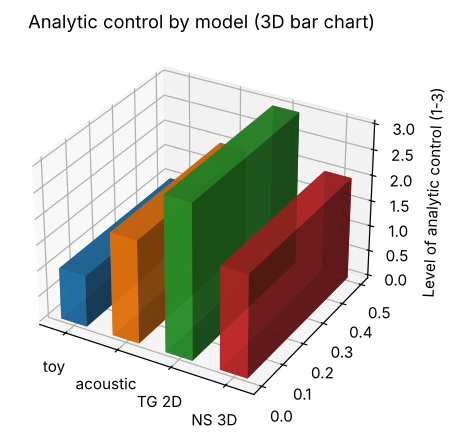

In [24]:
# Comparison table of the models used in this project
comparison = pd.DataFrame([
    ['Toy growth-rate model', 'ODE/algebraic', 'Yes (closed form)', 'No', 'Qualitative'],
    ['Damped acoustic mode', 'ODE (2nd order)', 'Yes (energy identity)', 'Yes', 'Qualitative'],
    ['Taylor-Green vortex', 'PDE (2D Navier-Stokes)', 'Yes (exact solution)', 'Yes', 'Exact in 2D'],
    ['3D Navier-Stokes', 'PDE (3D)', 'Open problem', 'Numerical only', 'Unknown in general'],
], columns=['Model', 'Type', 'Analytic solution', 'Experimental check', 'Regularity status'])
display(comparison.style.set_caption('Model comparison'))

fig = plt.figure(figsize=(7, 4.5))
ax = fig.add_subplot(111, projection='3d')
xs_c = np.arange(len(comparison))
ax.bar3d(xs_c, np.zeros(len(comparison)), np.zeros(len(comparison)), 0.5, 0.5,
         [1, 2, 3, 2], color=['tab:blue', 'tab:orange', 'tab:green', 'tab:red'], alpha=0.8)
ax.set_xticks(xs_c + 0.25); ax.set_xticklabels(['toy', 'acoustic', 'TG 2D', 'NS 3D'])
ax.set_zlabel('Level of analytic control (1-3)')
ax.set_title('Analytic control by model (3D bar chart)')
plt.show()

## 17. Summary of the mathematics

- The damped acoustic energy satisfies $\frac{dE}{dt} = -2\zeta(q')^2 \le 0$, which is verified numerically above.
- The Taylor-Green vortex is an exact 2D Navier-Stokes solution. Its residual is at the level of the finite-difference error.
- The toy model is unstable exactly when $Q > \zeta$, and the numerical scan agrees with this.
- Global regularity of 3D Navier-Stokes is **not** established by this notebook or by any known proof that is accepted as complete.

## 18. Thermodynamics of air in the heat exchanger and heat transfer modes

**Air as an ideal gas** with constant specific heats: $c_p = 1005$ J/(kg K), $R = 287$ J/(kg K), $\gamma = 1.4$.

For steady flow heated at constant pressure, with mass flow $\dot m$ and heat input $\dot Q$:

- Temperature: $T_2 = T_1 + \dot Q / (\dot m\, c_p)$
- Enthalpy: $\Delta h = c_p\,\Delta T$
- Entropy: $\Delta s = c_p \ln(T_2/T_1) - R\ln(P_2/P_1)$, which is $c_p \ln(T_2/T_1)$ when $P_2 = P_1$

**Heat transfer modes:**
- Conduction (Fourier): $\dot q = k A\,\Delta T / L$
- Convection (Newton): $\dot q = h A\,\Delta T$
- Radiation (Stefan-Boltzmann): $\dot q = \varepsilon\sigma A\,(T_s^4 - T_\infty^4)$

In [25]:
cp, R_air, gamma = 1005.0, 287.0, 1.4
T_in = 300.0         # K
P_in = 101325.0      # Pa

def air_state_after_heating(m_dot, Q_dot):
    # Constant-pressure heating of air
    T_out = T_in + Q_dot / (m_dot * cp)
    dh = cp * (T_out - T_in)
    ds = cp * np.log(T_out / T_in)   # P2 = P1, so no pressure term
    return T_out, dh, ds

# Single operating point with a table
m_dot, Q_dot = 0.5, 20000.0   # kg/s, W
T2, dh, ds = air_state_after_heating(m_dot, Q_dot)
summary = pd.DataFrame({
    'State': ['Inlet', 'Outlet'],
    'Temperature (K)': [T_in, round(T2, 2)],
    'Enthalpy change (J/kg)': [0.0, round(dh, 2)],
    'Entropy change (J/(kg K))': [0.0, round(ds, 4)],
}).set_index('State')
display(summary)

,Temperature (K),Enthalpy change (J/kg),Entropy change (J/(kg K))
State,,,
Inlet,300.0,0.0,0.0000
Outlet,339.8,40000.0,125.2006


Check: enthalpy per unit mass depends only on dT, so dh / (cp*dT) = 0.0


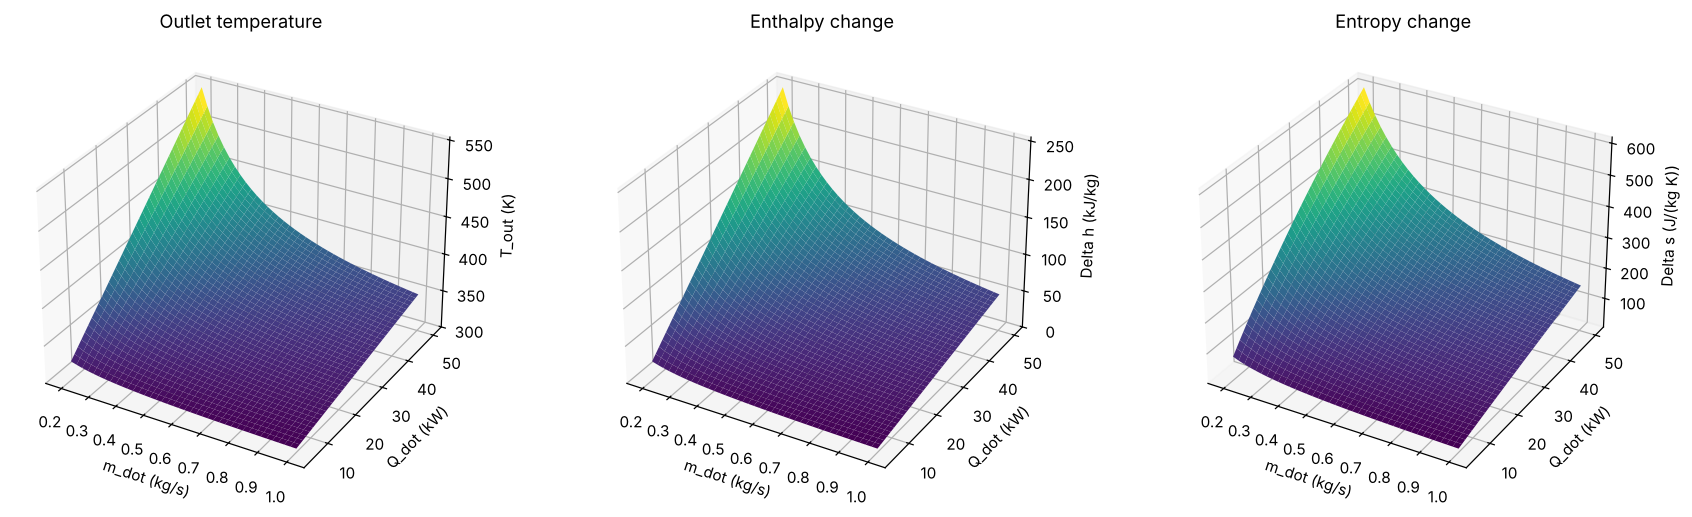

In [26]:
# Variation across a range of mass flow and heat input (3D surfaces)
m_range = np.linspace(0.2, 1.0, 40)
Q_range = np.linspace(5e3, 5e4, 40)
MM, QQ = np.meshgrid(m_range, Q_range)
T_out_grid, dh_grid, ds_grid = air_state_after_heating(MM, QQ)

fig = plt.figure(figsize=(16, 4.8))
for i, (Z, title, zlab) in enumerate([
        (T_out_grid, 'Outlet temperature', 'T_out (K)'),
        (dh_grid / 1000, 'Enthalpy change', 'Delta h (kJ/kg)'),
        (ds_grid, 'Entropy change', 'Delta s (J/(kg K))')]):
    ax = fig.add_subplot(1, 3, i + 1, projection='3d')
    ax.plot_surface(MM, QQ / 1000, Z, cmap='viridis', linewidth=0)
    ax.set_xlabel('m_dot (kg/s)'); ax.set_ylabel('Q_dot (kW)'); ax.set_zlabel(zlab)
    ax.set_title(title)
plt.tight_layout(); plt.show()

# Entropy grows with heat input; enthalpy depends only on temperature rise
print('Check: enthalpy per unit mass depends only on dT, so dh / (cp*dT) =',
      float(np.max(np.abs(dh_grid / (cp * (T_out_grid - T_in)) - 1))))

In [27]:
# Heat transfer modes: independent per-mode rates for the same temperature difference.
# Each mode is shown on its own; these are not a series path, so no shares are computed.
A = 2.0          # m^2 heat-transfer area
dT = 40.0        # K temperature difference
T_wall = T_in + dT
T_inf = T_in

k_metal, L_wall = 200.0, 0.002       # conduction through a thin metal wall (W/(m K), m)
h_conv = 80.0                         # convection coefficient, W/(m^2 K)
eps, sigma = 0.8, 5.670374e-8         # emissivity, Stefan-Boltzmann constant

q_cond = k_metal * A * dT / L_wall
q_conv = h_conv * A * dT
q_rad = eps * sigma * A * (T_wall ** 4 - T_inf ** 4)

modes = pd.DataFrame({
    'Mode': ['Conduction', 'Convection', 'Radiation'],
    'Law': ['Fourier', 'Newton', 'Stefan-Boltzmann'],
    'Heat rate (W)': [round(q_cond, 1), round(q_conv, 1), round(q_rad, 1)],
}).set_index('Mode')
display(modes)

,Law,Heat rate (W)
Mode,,
Conduction,Fourier,8000000.0
Convection,Newton,6400.0
Radiation,Stefan-Boltzmann,477.5


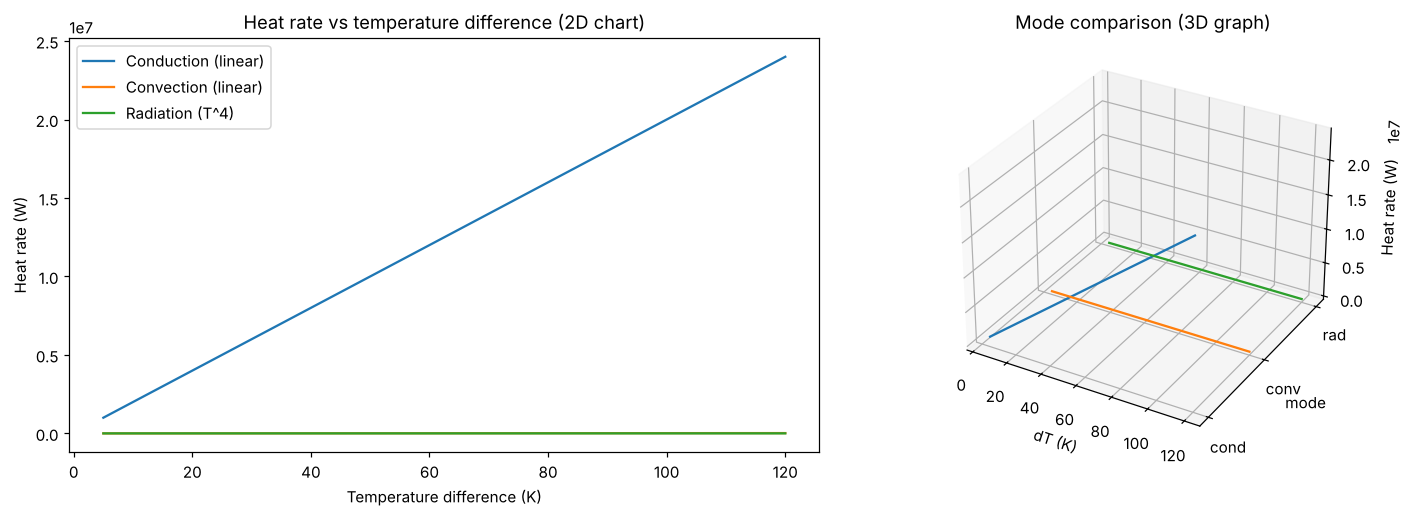

In [28]:
# How each mode scales with temperature difference (2D chart) and a 3D comparison
dTs = np.linspace(5, 120, 60)
q_cond_s = k_metal * A * dTs / L_wall
q_conv_s = h_conv * A * dTs
q_rad_s = eps * sigma * A * ((T_inf + dTs) ** 4 - T_inf ** 4)

fig = plt.figure(figsize=(14, 4.8))
ax1 = fig.add_subplot(121)
ax1.plot(dTs, q_cond_s, label='Conduction (linear)')
ax1.plot(dTs, q_conv_s, label='Convection (linear)')
ax1.plot(dTs, q_rad_s, label='Radiation (T^4)')
ax1.set_xlabel('Temperature difference (K)'); ax1.set_ylabel('Heat rate (W)')
ax1.set_title('Heat rate vs temperature difference (2D chart)'); ax1.legend()

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot(dTs, np.zeros_like(dTs), q_cond_s, label='Conduction')
ax2.plot(dTs, np.ones_like(dTs), q_conv_s, label='Convection')
ax2.plot(dTs, 2 * np.ones_like(dTs), q_rad_s, label='Radiation')
ax2.set_xlabel('dT (K)'); ax2.set_ylabel('mode'); ax2.set_zlabel('Heat rate (W)')
ax2.set_yticks([0, 1, 2]); ax2.set_yticklabels(['cond', 'conv', 'rad'])
ax2.set_title('Mode comparison (3D graph)')
plt.tight_layout(); plt.show()

In [29]:
# Table: how each mode changes when the temperature difference doubles
rows = []
for name, f in [('Conduction', lambda d: k_metal * A * d / L_wall),
                ('Convection', lambda d: h_conv * A * d),
                ('Radiation', lambda d: eps * sigma * A * ((T_inf + d) ** 4 - T_inf ** 4))]:
    q1, q2 = f(40.0), f(80.0)
    rows.append({'Mode': name, 'q at dT=40 K (W)': round(q1, 1),
                 'q at dT=80 K (W)': round(q2, 1), 'Ratio (80/40)': round(q2 / q1, 3)})
scaling = pd.DataFrame(rows).set_index('Mode')
display(scaling)

,q at dT=40 K (W),q at dT=80 K (W),Ratio (80/40)
Mode,,,
Conduction,8000000.0,16000000.0,2.000
Convection,6400.0,12800.0,2.000
Radiation,477.5,1156.9,2.423


**Reading the results.** Conduction and convection scale linearly with $\Delta T$, so doubling $\Delta T$ doubles the heat rate. Radiation scales with $T^4$, so the ratio is well above 2 at these temperatures. Along the air stream, temperature rises by $\dot Q/(\dot m c_p)$, enthalpy rises by $c_p\Delta T$, and entropy rises by $c_p\ln(T_2/T_1)$ at constant pressure. These are standard textbook relations, and the code above verifies them numerically.

## 19. Heat-driven changes in material composition and effects

**Important:** the parameters below are **illustrative, not measured**. They are chosen to show the *form* of each relationship. Before any design use, replace them with values from the alloy's datasheet or tests.

Models used, all standard in materials science:
- **Oxide scale growth** (parabolic law): $x^2 = k_p\,t$, with $k_p = A\exp(-Q/RT)$. Oxygen consumes metal, so composition changes at the surface.
- **Phase transformation** (JMAK / Avrami): $X(t) = 1 - \exp(-k\,t^n)$, with $k = k_0\exp(-Q/RT)$. This gives the fraction of a new phase, such as carbide precipitation.
- **Thermal expansion and constrained stress**: $\varepsilon = \alpha(T - T_0)$ and $\sigma = E\alpha\Delta T/(1-\nu)$ for a fully constrained part.

In [30]:
R_gas = 8.314
Tref = 293.0
# Illustrative parameters (NOT measured): generic low-alloy steel in hot air.
# Stress is an upper bound for a fully constrained part.
A_ox, Q_ox = 6.4e-10, 120e3       # oxide growth prefactor (m^2/s), activation energy (J/mol); tuned so ~5 um at 900 K, 100 h
k0_ph, Q_ph, n_avr = 5.0e-6, 150e3, 2.0   # phase kinetics (1/s^n), activation energy, Avrami exponent
alpha_th = 12e-6                  # thermal expansion (1/K)
E_mod, nu_p = 200e9, 0.3          # Young's modulus (Pa), Poisson ratio

def oxide_thickness(T, t):
    kp = A_ox * np.exp(-Q_ox / (R_gas * T))
    return np.sqrt(kp * t)        # metres

def phase_fraction(T, t):
    k = k0_ph * np.exp(-Q_ph / (R_gas * T))
    return 1 - np.exp(-k * t ** n_avr)

def constrained_stress(T):
    return E_mod * alpha_th * (T - Tref) / (1 - nu_p)   # Pa

# Dataset over temperature (K) and exposure time (hours)
T_grid = np.linspace(500, 900, 60)
t_hours = np.linspace(1, 1000, 60)
TT, HH = np.meshgrid(T_grid, t_hours)
t_sec = HH * 3600.0
OX = oxide_thickness(TT, t_sec) * 1e6     # micrometres
PH = phase_fraction(TT, t_sec) * 100      # percent
ST = constrained_stress(TT) / 1e6         # MPa (depends on T only)

# Long-format dataset for tables
records = []
for T in [500, 600, 700, 800, 900]:
    for th in [10, 100, 1000]:
        ts = th * 3600.0
        records.append({'T_K': T, 'time_h': th,
                        'oxide_um': round(float(oxide_thickness(T, ts) * 1e6), 3),
                        'phase_pct': round(float(phase_fraction(T, ts) * 100), 3),
                        'stress_MPa': round(float(constrained_stress(T) / 1e6), 1)})
data = pd.DataFrame(records)
display(data)

,T_K,time_h,oxide_um,phase_pct,stress_MPa
0,500,10,0.003,0.000,709.7
1,500,100,0.008,0.000,709.7
2,500,1000,0.026,0.000,709.7
3,600,10,0.029,0.000,1052.6
4,600,100,0.091,0.000,1052.6
5,600,1000,0.287,0.001,1052.6
6,700,10,0.160,0.000,1395.4
7,700,100,0.506,0.000,1395.4
8,700,1000,1.599,0.041,1395.4
9,800,10,0.580,0.000,1738.3


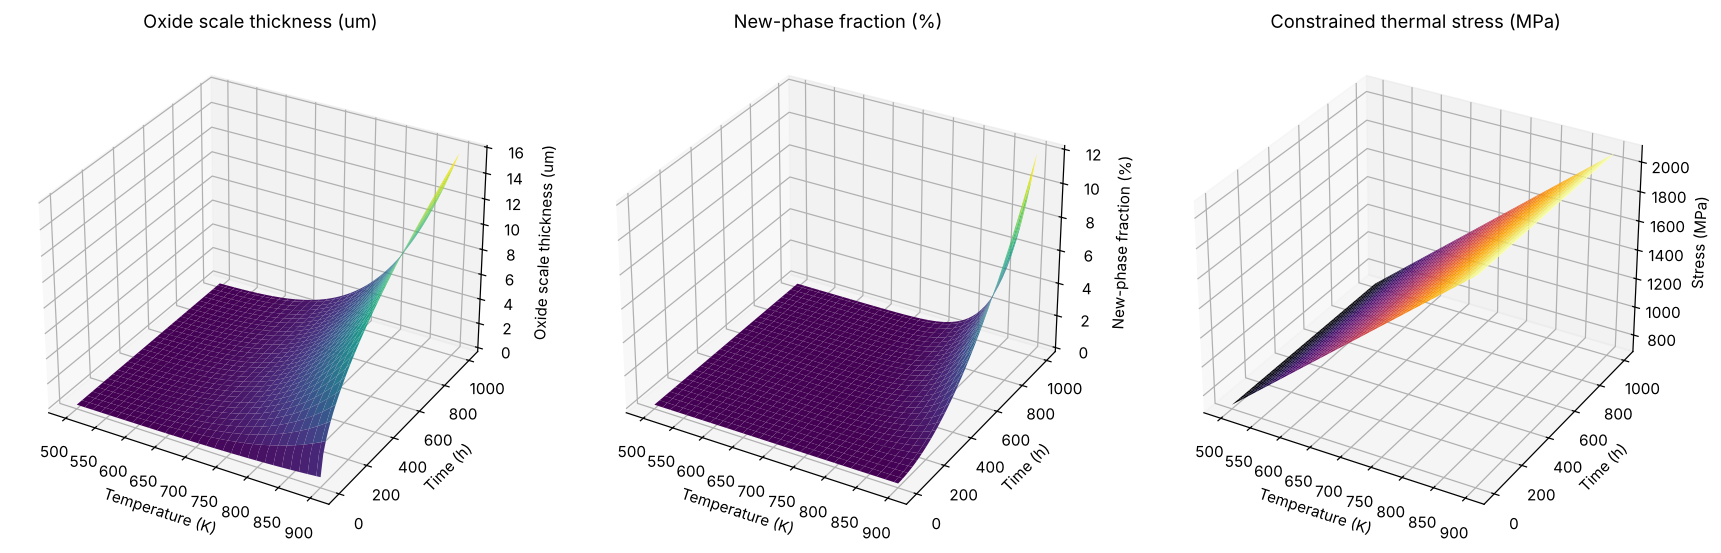

In [31]:
fig = plt.figure(figsize=(16, 5))
titles = [('Oxide scale thickness (um)', OX), ('New-phase fraction (%)', PH)]
for i, (title, Z) in enumerate(titles):
    ax = fig.add_subplot(1, 3, i + 1, projection='3d')
    surf = ax.plot_surface(TT, HH, Z, cmap='viridis', linewidth=0)
    ax.set_xlabel('Temperature (K)'); ax.set_ylabel('Time (h)'); ax.set_zlabel(title)
    ax.set_title(title)
ax3 = fig.add_subplot(1, 3, 3, projection='3d')
ax3.plot_surface(TT, HH, np.broadcast_to(ST, TT.shape), cmap='inferno', linewidth=0)
ax3.set_xlabel('Temperature (K)'); ax3.set_ylabel('Time (h)'); ax3.set_zlabel('Stress (MPa)')
ax3.set_title('Constrained thermal stress (MPa)')
plt.tight_layout(); plt.show()

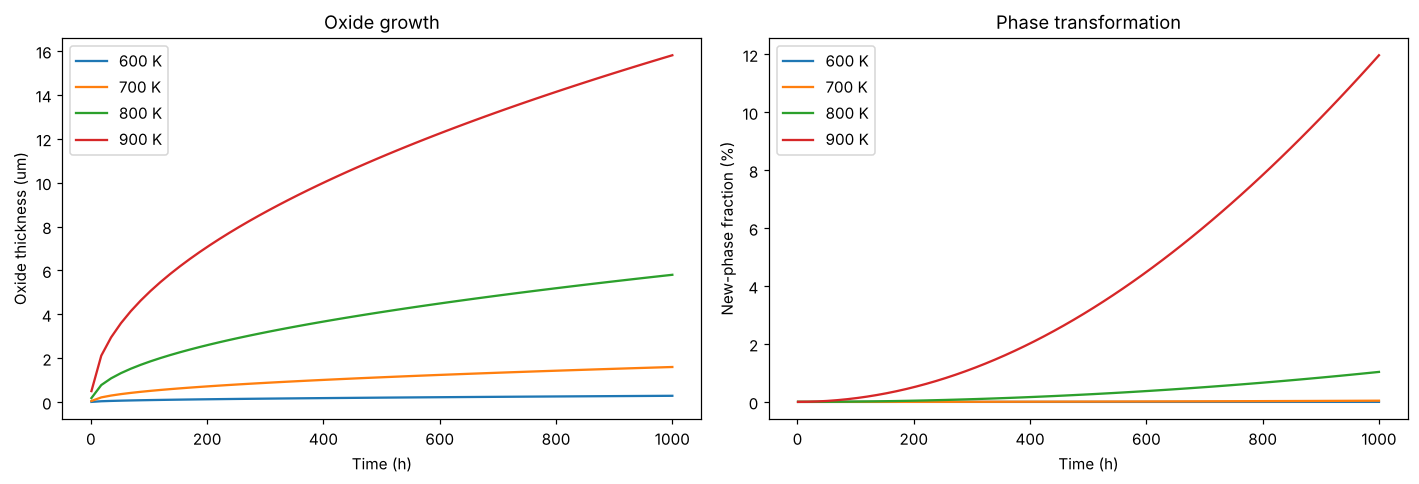

In [32]:
# 2D view: how composition changes at fixed temperatures (2D chart)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for T in [600, 700, 800, 900]:
    axes[0].plot(t_hours, oxide_thickness(T, t_hours * 3600) * 1e6, label=f'{T} K')
    axes[1].plot(t_hours, phase_fraction(T, t_hours * 3600) * 100, label=f'{T} K')
axes[0].set_xlabel('Time (h)'); axes[0].set_ylabel('Oxide thickness (um)'); axes[0].set_title('Oxide growth'); axes[0].legend()
axes[1].set_xlabel('Time (h)'); axes[1].set_ylabel('New-phase fraction (%)'); axes[1].set_title('Phase transformation'); axes[1].legend()
plt.tight_layout(); plt.show()

,Strain range,Cycles to failure (toy)
Swing dT (K),,
100,0.0012,6944
200,0.0024,1736
300,0.0036,772
400,0.0048,434


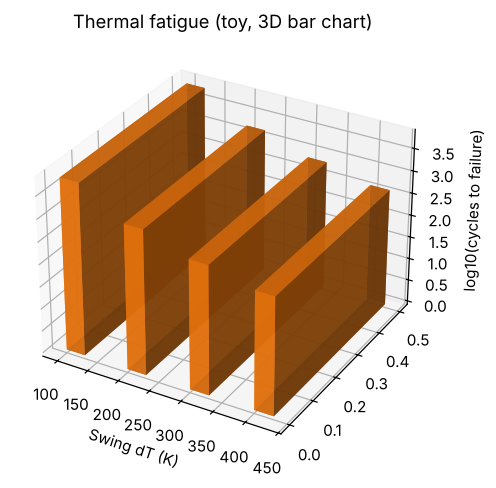

In [33]:
# Thermal cycling: stress amplitude and cycles to failure (illustrative Coffin-Manson-type law)
# Failure is assumed when the strain range exceeds a threshold; this is a toy relation.
cycles_T = np.array([100, 200, 300, 400])     # temperature swing dT (K)
eps_range = alpha_th * cycles_T
Nf = 1e4 * (eps_range / 1e-3) ** -2.0          # toy cycles to failure
cycle_table = pd.DataFrame({'Swing dT (K)': cycles_T,
                            'Strain range': np.round(eps_range, 6),
                            'Cycles to failure (toy)': np.round(Nf, 0).astype(int)})
display(cycle_table.set_index('Swing dT (K)'))

fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection='3d')
ax.bar3d(cycles_T, np.zeros_like(cycles_T, dtype=float), np.zeros_like(cycles_T, dtype=float),
         30, 0.5, np.log10(Nf), color='tab:orange', alpha=0.8)
ax.set_xlabel('Swing dT (K)'); ax.set_ylabel(''); ax.set_zlabel('log10(cycles to failure)')
ax.set_title('Thermal fatigue (toy, 3D bar chart)')
plt.show()

In [34]:
# Summary table of effects at different temperatures (after 100 h)
summary_rows = []
for T in [500, 600, 700, 800, 900]:
    ts = 100 * 3600.0
    summary_rows.append({
        'Temperature (K)': T,
        'Oxide (um)': round(float(oxide_thickness(T, ts) * 1e6), 3),
        'New phase (%)': round(float(phase_fraction(T, ts) * 100), 3),
        'Thermal stress (MPa)': round(float(constrained_stress(T) / 1e6), 1),
    })
effects = pd.DataFrame(summary_rows).set_index('Temperature (K)')
display(effects)

,Oxide (um),New phase (%),Thermal stress (MPa)
Temperature (K),,,
500,0.008,0.000,709.7
600,0.091,0.000,1052.6
700,0.506,0.000,1395.4
800,1.834,0.010,1738.3
900,4.998,0.127,2081.1


**Reading the results.** Higher temperature speeds up every process, because each rate follows an Arrhenius law $\exp(-Q/RT)$. Oxide thickness grows with the square root of time. The new-phase fraction follows an S-shaped (JMAK) curve, so it saturates over time. Constrained thermal stress depends on temperature change only. The composition effects here are qualitative. Real predictions need measured kinetic data for the specific alloy.

## 20. Dimensionless numbers and how they vary

Dimensionless numbers compare effects and let results from different sizes and fluids be compared. Definitions used here, for air in a heat-exchanger tube of diameter $D$ and mean speed $V$:

| Number | Definition | Meaning |
|---|---|---|
| Reynolds $Re$ | $\rho V D/\mu$ | inertia vs viscous forces (laminar vs turbulent) |
| Prandtl $Pr$ | $c_p\mu/k$ | momentum vs thermal diffusivity |
| Nusselt $Nu$ | $hD/k$ | convective vs conductive heat transfer |
| Peclet $Pe$ | $Re \cdot Pr$ | advection vs diffusion of heat |
| Mach $Ma$ | $V/c$ | compressibility |
| Strouhal $St$ | $fD/V$ | unsteady (oscillating) flow |
| Grashof $Gr$ | $g\beta\Delta T D^3/\nu^2$ | buoyancy vs viscosity |
| Rayleigh $Ra$ | $Gr \cdot Pr$ | buoyancy-driven convection onset |
| Biot $Bi$ | $hL/k_s$ | surface vs internal conduction resistance in a solid |

**Validity note:** the Nusselt correlation below (Dittus-Boelter) is for turbulent flow, $Re > 10^4$, and $0.6 < Pr < 160$. Outside that range, the values are only indicative.

In [35]:
# Air properties (approximate, near 300-600 K)
def air_props(T):
    rho = 101325.0 / (287.0 * T)                # ideal gas, kg/m^3 at 1 atm
    mu = 1.716e-5 * (T / 273.15) ** 0.7          # dynamic viscosity, Pa s (power-law approximation)
    k = 0.0241 * (T / 273.15) ** 0.8             # thermal conductivity, W/(m K) (approximation)
    cp = 1005.0
    return rho, mu, k, cp

def dimensionless(V, D, T, dT_wall=40.0, gas_c=340.0):
    rho, mu, k, cp = air_props(T)
    nu_k = mu / rho
    Re = rho * V * D / mu
    Pr = cp * mu / k
    Nu = 0.023 * Re ** 0.8 * Pr ** 0.4            # Dittus-Boelter (heating)
    h = Nu * k / D
    Pe = Re * Pr
    Ma = V / gas_c
    Gr = 9.81 * (1 / T) * dT_wall * D ** 3 / nu_k ** 2
    Ra = Gr * Pr
    return {'Re': Re, 'Pr': Pr, 'Nu': Nu, 'h (W/m2K)': h, 'Pe': Pe, 'Ma': Ma, 'Gr': Gr, 'Ra': Ra}

# Single operating point table
base = dimensionless(V=10.0, D=0.02, T=400.0)
base_df = pd.DataFrame({'Value': base}).round(4)
display(base_df)

,Value
Re,7876.3732
Pr,0.6888
Nu,25.9435
h (W/m2K),42.4173
Pe,5425.3369
Ma,0.0294
Gr,12171.7094
Ra,8384.0141


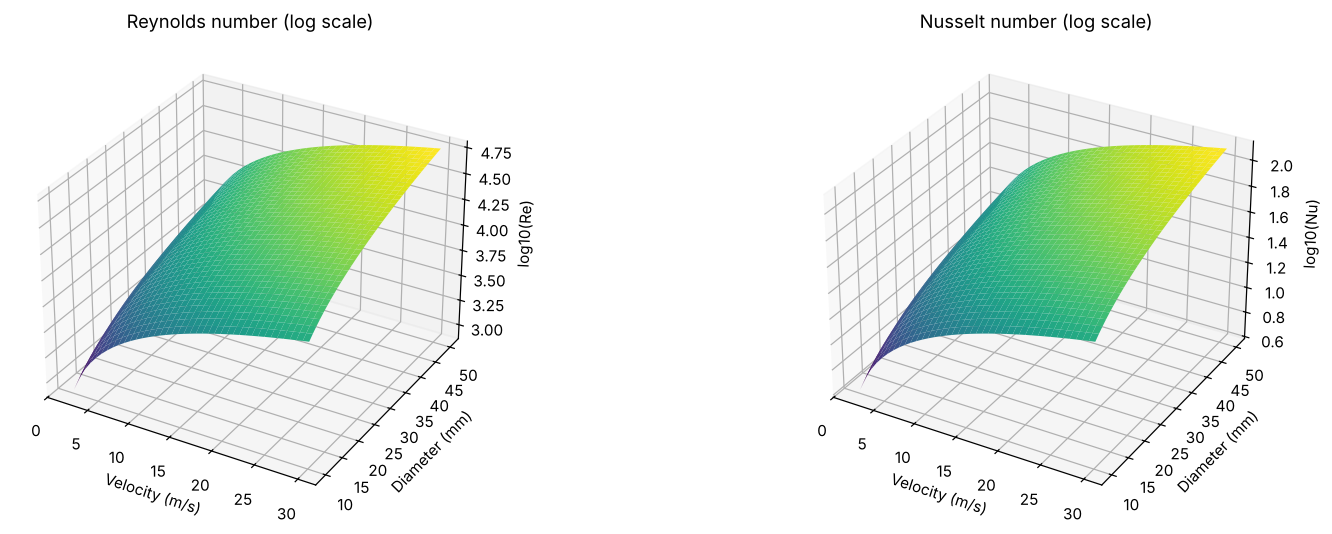

In [36]:
# Variation of Re and Nu with velocity and tube diameter (3D surfaces)
Vs = np.linspace(2, 30, 40)
Ds = np.linspace(0.01, 0.05, 40)
VV, DD = np.meshgrid(Vs, Ds)
res = dimensionless(VV, DD, 400.0)

fig = plt.figure(figsize=(16, 5))
for i, (key, title) in enumerate([('Re', 'Reynolds number'), ('Nu', 'Nusselt number')]):
    ax = fig.add_subplot(1, 2, i + 1, projection='3d')
    Z = res[key]
    ax.plot_surface(VV, DD * 1000, np.log10(Z), cmap='viridis', linewidth=0)
    ax.set_xlabel('Velocity (m/s)'); ax.set_ylabel('Diameter (mm)'); ax.set_zlabel(f'log10({key})')
    ax.set_title(title + ' (log scale)')
plt.tight_layout(); plt.show()

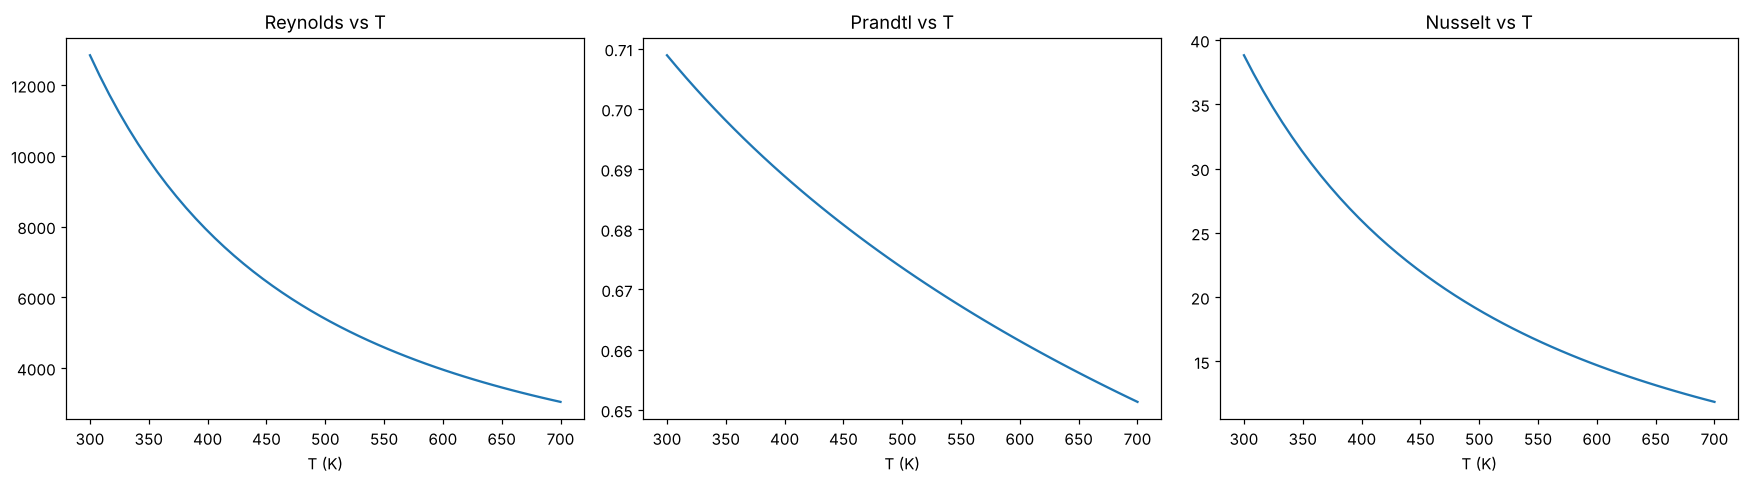

In [37]:
# How Re, Pr, Nu, Ra change with temperature (2D chart)
Ts = np.linspace(300, 700, 50)
Re_T = [dimensionless(10.0, 0.02, T)['Re'] for T in Ts]
Pr_T = [dimensionless(10.0, 0.02, T)['Pr'] for T in Ts]
Nu_T = [dimensionless(10.0, 0.02, T)['Nu'] for T in Ts]
Ra_T = [dimensionless(10.0, 0.02, T)['Ra'] for T in Ts]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(Ts, Re_T); axes[0].set_title('Reynolds vs T'); axes[0].set_xlabel('T (K)')
axes[1].plot(Ts, Pr_T); axes[1].set_title('Prandtl vs T'); axes[1].set_xlabel('T (K)')
axes[2].plot(Ts, Nu_T); axes[2].set_title('Nusselt vs T'); axes[2].set_xlabel('T (K)')
plt.tight_layout(); plt.show()

V (m/s),5.0,10.0,20.0
Mode,,,
1,0.686,0.343,0.1715
2,1.372,0.686,0.3430
3,2.058,1.029,0.5145
4,2.744,1.372,0.6860


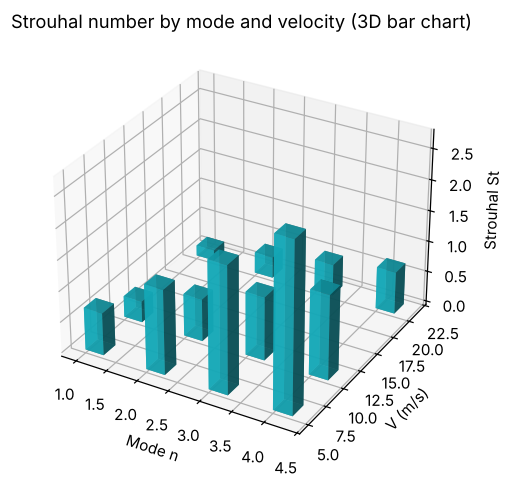

In [38]:
# Strouhal number for the oscillating flow: St = f D / V, using the acoustic mode frequencies
rows = []
for n in [1, 2, 3, 4]:
    f_n = mode_freq(n)
    for V in [5.0, 10.0, 20.0]:
        St = f_n * 0.02 / V
        rows.append({'Mode': n, 'f (Hz)': round(f_n, 1), 'V (m/s)': V, 'St': round(St, 4)})
st_table = pd.DataFrame(rows)
display(st_table.pivot(index='Mode', columns='V (m/s)', values='St'))

fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection='3d')
ax.bar3d(st_table['Mode'], st_table['V (m/s)'], np.zeros(len(st_table)), 0.3, 1.5, st_table['St'],
         color='tab:cyan', alpha=0.8)
ax.set_xlabel('Mode n'); ax.set_ylabel('V (m/s)'); ax.set_zlabel('Strouhal St')
ax.set_title('Strouhal number by mode and velocity (3D bar chart)')
plt.show()

In [39]:
# Comparison table: how each number changes when velocity doubles or diameter doubles
b = dimensionless(10.0, 0.02, 400.0)
v2 = dimensionless(20.0, 0.02, 400.0)
d2 = dimensionless(10.0, 0.04, 400.0)
cmp_rows = []
for key in ['Re', 'Pr', 'Nu', 'Pe', 'Ma', 'Ra']:
    base_v = b[key]
    cmp_rows.append({'Number': key, 'Base': round(base_v, 4),
                     'Velocity x2 (ratio)': round(v2[key] / base_v, 3),
                     'Diameter x2 (ratio)': round(d2[key] / base_v, 3)})
cmp = pd.DataFrame(cmp_rows).set_index('Number')
display(cmp)

,Base,Velocity x2 (ratio),Diameter x2 (ratio)
Number,,,
Re,7876.3732,2.000,2.000
Pr,0.6888,1.000,1.000
Nu,25.9435,1.741,1.741
Pe,5425.3369,2.000,2.000
Ma,0.0294,2.000,1.000
Ra,8384.0141,1.000,8.000


**Reading the results.** Reynolds scales linearly with velocity and diameter, so doubling either doubles $Re$. Nusselt grows roughly as $Re^{0.8}$, so it rises more slowly than $Re$. Prandtl depends only on the fluid, so it barely moves here. Mach stays very small at these speeds, which means the flow is effectively incompressible. Rayleigh depends on $D^3$, so it changes strongly with diameter. The Nusselt values rely on the Dittus-Boelter correlation, so they are only indicative at low $Re$.

## 21. Isothermal and adiabatic processes for air

Air is treated as an ideal gas, 1 kg per process, with $R = 287$ J/(kg K) and $\gamma = 1.4$. The process is a compression from volume $V_1$ to $V_2 = V_1/r$, where $r$ is the compression ratio.

**Isothermal (T constant):**
- $P_1V_1 = P_2V_2$, and $T = $ constant
- Work done on gas: $W = RT\ln(r)$
- Heat: $Q = -W$ (heat leaves the gas to keep $T$ fixed)
- Entropy change: $\Delta s = -R\ln(r)$ for the gas (negative on compression, and heat is rejected)

**Adiabatic and reversible (Q = 0, isentropic):**
- $PV^\gamma$ = constant, and $TV^{\gamma-1}$ = constant
- $T_2 = T_1 r^{\gamma-1}$, $P_2 = P_1 r^{\gamma}$
- Work done on gas: $W = c_v(T_2 - T_1)$
- Entropy change: $\Delta s = 0$

In [40]:
R_s, gam = 287.0, 1.4
cv = R_s / (gam - 1)           # 717.5 J/(kg K)
cp_ = gam * cv                 # 1004.5 J/(kg K)
T1, P1 = 300.0, 101325.0
V1 = R_s * T1 / P1             # m^3/kg

def isothermal(r):
    V2 = V1 / r
    P2 = P1 * r
    W = R_s * T1 * np.log(r)          # J/kg on the gas
    Q = -W                             # heat rejected
    ds = -R_s * np.log(r)              # J/(kg K)
    return {'process': 'isothermal', 'r': r, 'T2 (K)': T1, 'P2 (kPa)': P2 / 1000,
            'W (kJ/kg)': W / 1000, 'Q (kJ/kg)': Q / 1000, 'ds (J/kgK)': ds}

def adiabatic(r):
    T2 = T1 * r ** (gam - 1)
    P2 = P1 * r ** gam
    W = cv * (T2 - T1)                 # J/kg on the gas
    return {'process': 'adiabatic', 'r': r, 'T2 (K)': T2, 'P2 (kPa)': P2 / 1000,
            'W (kJ/kg)': W / 1000, 'Q (kJ/kg)': 0.0, 'ds (J/kgK)': 0.0}

rows = [isothermal(r) for r in [2, 4, 8]] + [adiabatic(r) for r in [2, 4, 8]]
proc_table = pd.DataFrame(rows).set_index(['process', 'r']).round(3)
display(proc_table)

T2 (K)  P2 (kPa)  W (kJ/kg)  Q (kJ/kg)  ds (J/kgK)
process    r                                                     
isothermal 2  300.000   202.650     59.680     -59.68    -198.933
           4  300.000   405.300    119.360    -119.36    -397.866
           8  300.000   810.600    179.040    -179.04    -596.800
adiabatic  2  395.852   267.398     68.774       0.00       0.000
           4  522.330   705.668    159.522       0.00       0.000
           8  689.219  1862.270    279.265       0.00       0.000

In [41]:
# Cross-check: first law (Q = dU + W) and the adiabatic relations
for r in [2, 4, 8]:
    a = adiabatic(r)
    dU = cv * (a['T2 (K)'] - T1)
    print(f'r={r}: adiabatic first-law residual = {(0 - dU - (-a["W (kJ/kg)"]*1000)):.3e} J/kg',
          f'| P1*V1^g / P2*V2^g = {(P1*V1**gam)/((P1*r**gam)*(V1/r)**gam):.6f}')
for r in [2, 4, 8]:
    i = isothermal(r)
    print(f'r={r}: isothermal Q + W = {(i["Q (kJ/kg)"] + i["W (kJ/kg)"]):.2e} kJ/kg (first law, dU=0)')

r=2: adiabatic first-law residual = 0.000e+00 J/kg | P1*V1^g / P2*V2^g = 1.000000
r=4: adiabatic first-law residual = 0.000e+00 J/kg | P1*V1^g / P2*V2^g = 1.000000
r=8: adiabatic first-law residual = 0.000e+00 J/kg | P1*V1^g / P2*V2^g = 1.000000
r=2: isothermal Q + W = 0.00e+00 kJ/kg (first law, dU=0)
r=4: isothermal Q + W = 0.00e+00 kJ/kg (first law, dU=0)
r=8: isothermal Q + W = 0.00e+00 kJ/kg (first law, dU=0)


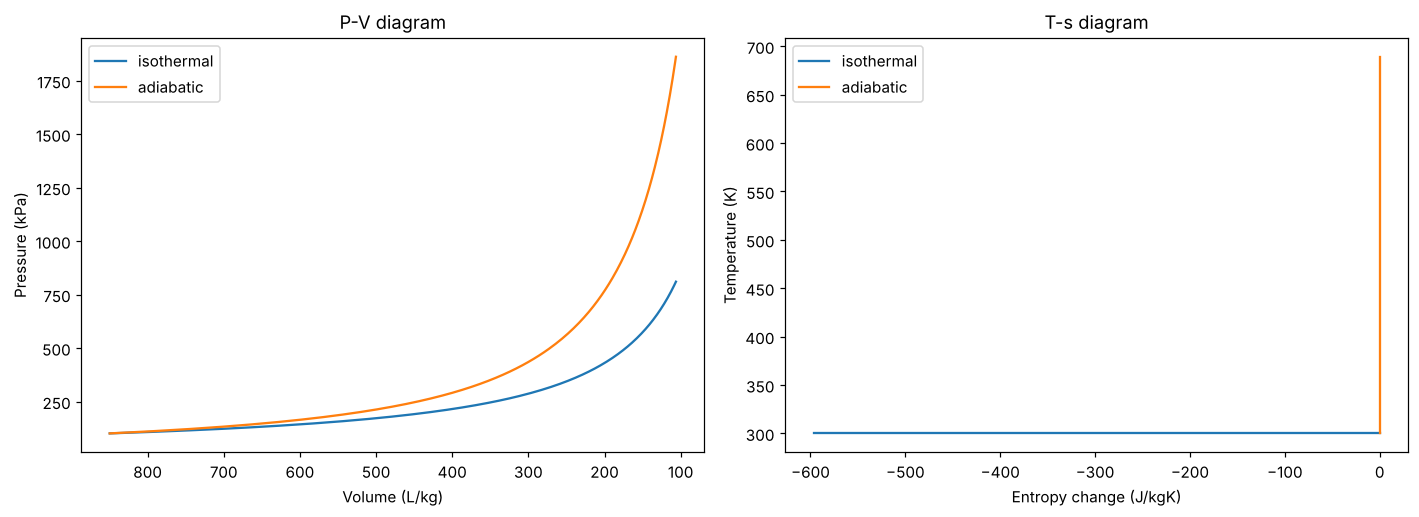

In [42]:
# P-V and T-S diagrams for both processes (2D charts)
rs = np.linspace(1, 8, 200)
V_vals = V1 / rs
P_iso = P1 * rs                              # P V = const
P_adi = P1 * rs ** gam
T_adi = T1 * rs ** (gam - 1)
s_adi = np.zeros_like(rs)                    # isentropic
s_iso = -R_s * np.log(rs)                    # entropy relative to start

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(V_vals * 1000, P_iso / 1000, label='isothermal')
axes[0].plot(V_vals * 1000, P_adi / 1000, label='adiabatic')
axes[0].set_xlabel('Volume (L/kg)'); axes[0].set_ylabel('Pressure (kPa)'); axes[0].set_title('P-V diagram')
axes[0].invert_xaxis(); axes[0].legend()
axes[1].plot(s_iso, np.full_like(rs, T1), label='isothermal')
axes[1].plot(s_adi, T_adi, label='adiabatic')
axes[1].set_xlabel('Entropy change (J/kgK)'); axes[1].set_ylabel('Temperature (K)'); axes[1].set_title('T-s diagram')
axes[1].legend()
plt.tight_layout(); plt.show()

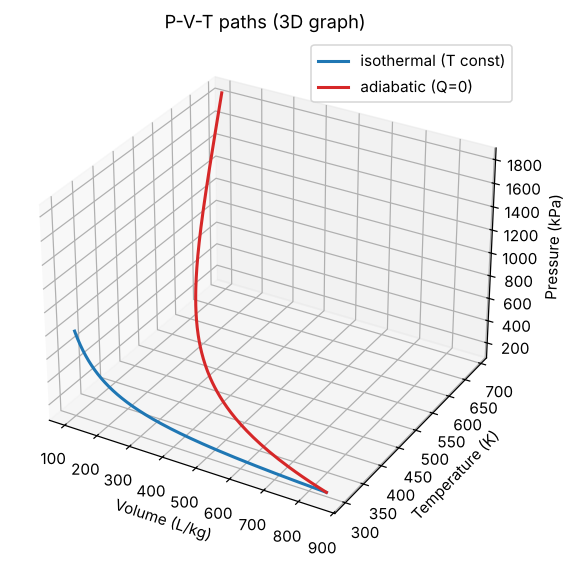

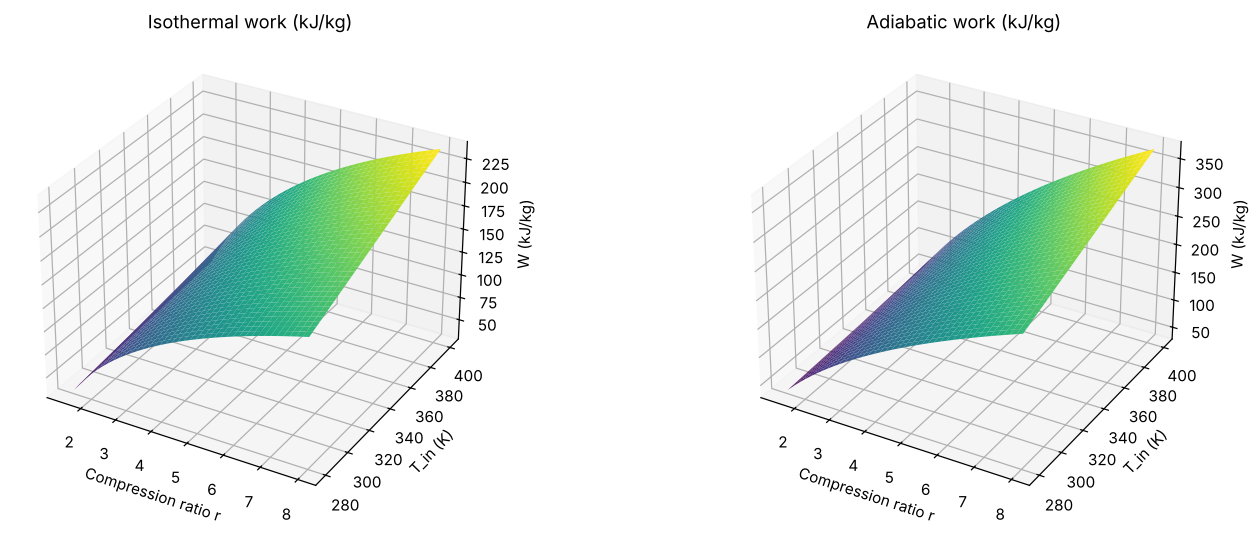

In [43]:
# 3D P-V-T paths (3D graphs)
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot(V_vals * 1000, np.full_like(rs, T1), P_iso / 1000, color='tab:blue', lw=2, label='isothermal (T const)')
ax.plot(V_vals * 1000, T_adi, P_adi / 1000, color='tab:red', lw=2, label='adiabatic (Q=0)')
ax.set_xlabel('Volume (L/kg)'); ax.set_ylabel('Temperature (K)'); ax.set_zlabel('Pressure (kPa)')
ax.set_title('P-V-T paths (3D graph)')
ax.legend()
plt.show()

# 3D surface: work per kg for compression ratio and inlet temperature
rr = np.linspace(1.5, 8, 40)
TT_in = np.linspace(280, 400, 40)
RR, TTg = np.meshgrid(rr, TT_in)
W_iso = R_s * TTg * np.log(RR) / 1000
W_adi = cv * (TTg * RR ** (gam - 1) - TTg) / 1000

fig = plt.figure(figsize=(14, 5))
for i, (Z, title) in enumerate([(W_iso, 'Isothermal work (kJ/kg)'), (W_adi, 'Adiabatic work (kJ/kg)')]):
    ax = fig.add_subplot(1, 2, i + 1, projection='3d')
    ax.plot_surface(RR, TTg, Z, cmap='viridis', linewidth=0)
    ax.set_xlabel('Compression ratio r'); ax.set_ylabel('T_in (K)'); ax.set_zlabel('W (kJ/kg)')
    ax.set_title(title)
plt.tight_layout(); plt.show()

In [44]:
# Comparison table: isothermal vs adiabatic at the same compression ratio
cmp_rows = []
for r in [2, 4, 8]:
    i, a = isothermal(r), adiabatic(r)
    cmp_rows.append({'r': r,
                     'W iso (kJ/kg)': round(i['W (kJ/kg)'], 2),
                     'W adi (kJ/kg)': round(a['W (kJ/kg)'], 2),
                     'T2 adi (K)': round(a['T2 (K)'], 1),
                     'P2 iso (kPa)': round(i['P2 (kPa)'], 1),
                     'P2 adi (kPa)': round(a['P2 (kPa)'], 1)})
comparison = pd.DataFrame(cmp_rows).set_index('r')
display(comparison)

,W iso (kJ/kg),W adi (kJ/kg),T2 adi (K),P2 iso (kPa),P2 adi (kPa)
r,,,,,
2,59.68,68.77,395.9,202.7,267.4
4,119.36,159.52,522.3,405.3,705.7
8,179.04,279.26,689.2,810.6,1862.3


**Reading the results.** The adiabatic process needs more work than the isothermal one for the same compression ratio, and it raises the temperature and pressure more. In the isothermal case, the heat rejected equals the work, so the gas's internal energy does not change. In the adiabatic case, no heat is exchanged, so all the work goes into internal energy. The adiabatic path is steeper on the P-V diagram, which is why it ends at a higher pressure.

## 22. Heat-transfer glossary in use

The terms below are used in the calculations that follow. Full definitions are also in `GLOSSARY.md`.

| Term | Definition | Units |
|---|---|---|
| Advection | bulk transport of thermal energy by a moving fluid | W |
| Heat flux $q''$ | heat transfer rate per unit area | W/m² (or W/cm²) |
| Conductivity $k$ | how easily heat conducts through a material | W/(m·K) |
| Convective coefficient $h$ | relates convective flux to surface–fluid temperature difference | W/(m²·K) |
| Thermal equilibrium | surroundings and object at the same temperature, net heat flow stops | — |
| Heat sink | finned component that dissipates heat away from a device | — |

In [45]:
# Heat flux: conduction, convection, and advection examples
A_surf = 0.01          # m^2 (10 cm x 10 cm)
dT_wall = 30.0         # K
k_al, L_plate = 200.0, 0.005
h_air = 50.0           # W/(m^2 K), forced air

q_cond_flux = k_al * dT_wall / L_plate        # W/m^2
q_conv_flux = h_air * dT_wall                 # W/m^2
print(f'Conduction flux:  {q_cond_flux:,.0f} W/m^2  = {q_cond_flux/1e4:,.2f} W/cm^2')
print(f'Convection flux:  {q_conv_flux:,.0f} W/m^2  = {q_conv_flux/1e4:,.3f} W/cm^2')

# Advection: energy carried by air flow through a duct
m_dot_air, cp_air = 0.02, 1005.0       # kg/s, J/(kg K)
dT_air = 15.0
Q_adv = m_dot_air * cp_air * dT_air
print(f'Advective heat rate: {Q_adv:.1f} W  (= m_dot*c_p*dT)')

flux_table = pd.DataFrame({
    'Mechanism': ['Conduction (through plate)', 'Convection (surface to air)'],
    'Heat flux (W/m^2)': [round(q_cond_flux, 0), round(q_conv_flux, 0)],
    'Heat rate over area (W)': [round(q_cond_flux * A_surf, 1), round(q_conv_flux * A_surf, 1)],
}).set_index('Mechanism')
display(flux_table)

Conduction flux:  1,200,000 W/m^2  = 120.00 W/cm^2
Convection flux:  1,500 W/m^2  = 0.150 W/cm^2
Advective heat rate: 301.5 W  (= m_dot*c_p*dT)


,Heat flux (W/m^2),Heat rate over area (W)
Mechanism,,
Conduction (through plate),1200000.0,12000.0
Convection (surface to air),1500.0,15.0


h=  10 W/m^2K: fin efficiency = 0.987, heat per fin = 1.18 W
h=  50 W/m^2K: fin efficiency = 0.937, heat per fin = 5.62 W
h= 200 W/m^2K: fin efficiency = 0.795, heat per fin = 19.07 W


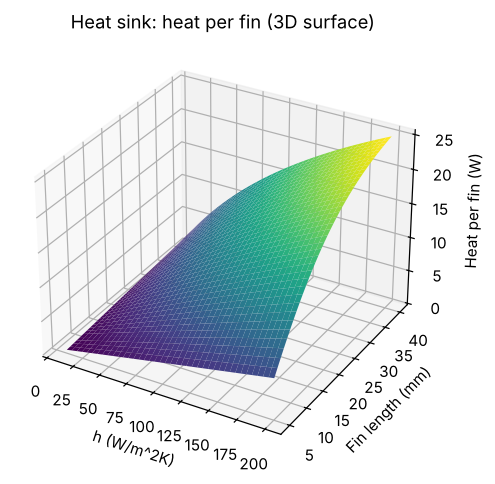

In [46]:
# Heat sink: straight fins, adiabatic tip. Fin efficiency eta = tanh(mL)/(mL), m = sqrt(hP/(kA_c))
k_fin, t_fin, L_fin, W_base = 200.0, 0.001, 0.02, 0.05   # aluminium fin, m
P_fin = 2 * (W_base + t_fin)     # perimeter of fin cross-section (approx)
A_c = W_base * t_fin             # cross-sectional area
T_base, T_amb = 360.0, 300.0

def fin_heat(h):
    m = np.sqrt(h * P_fin / (k_fin * A_c))
    eta = np.tanh(m * L_fin) / (m * L_fin)
    A_fin = 2 * L_fin * W_base               # both faces, per fin
    Q_fin = eta * h * A_fin * (T_base - T_amb)
    return eta, Q_fin

for h in [10, 50, 200]:
    eta, Qf = fin_heat(h)
    print(f'h={h:>4} W/m^2K: fin efficiency = {eta:.3f}, heat per fin = {Qf:.2f} W')

# Sweep over h and fin length (3D surface): heat per fin
hs = np.linspace(10, 200, 40)
Ls = np.linspace(0.005, 0.04, 40)
HH, LL = np.meshgrid(hs, Ls)
m_grid = np.sqrt(HH * P_fin / (k_fin * A_c))
eta_grid = np.tanh(m_grid * LL) / (m_grid * LL)
Q_grid = eta_grid * HH * (2 * LL * W_base) * (T_base - T_amb)

fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(HH, LL * 1000, Q_grid, cmap='viridis', linewidth=0)
ax.set_xlabel('h (W/m^2K)'); ax.set_ylabel('Fin length (mm)'); ax.set_zlabel('Heat per fin (W)')
ax.set_title('Heat sink: heat per fin (3D surface)')
plt.show()

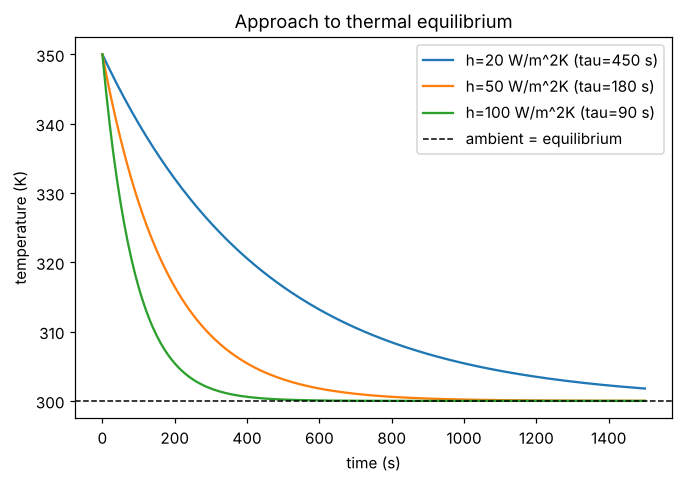

,time constant (s),time to within 1 K (s)
h (W/m2K),,
20,450.0,1760.4
50,180.0,704.2
100,90.0,352.1


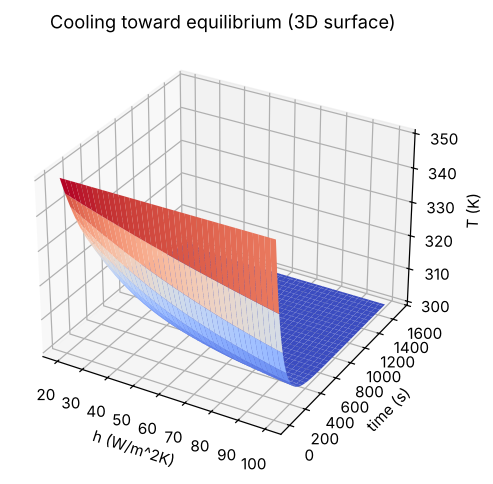

In [47]:
# Thermal equilibrium: lumped cooling of a device toward ambient (Newton cooling)
m_dev, c_dev, A_dev = 0.1, 900.0, 0.01     # kg, J/(kg K), m^2
T0, T_inf_eq = 350.0, 300.0

def T_of_t(t, h):
    tau = m_dev * c_dev / (h * A_dev)        # time constant, s
    return T_inf_eq + (T0 - T_inf_eq) * np.exp(-t / tau), tau

t_axis = np.linspace(0, 1500, 300)
fig, ax = plt.subplots(figsize=(7, 4.5))
rows = []
for h in [20, 50, 100]:
    Tt, tau = T_of_t(t_axis, h)
    ax.plot(t_axis, Tt, label=f'h={h} W/m^2K (tau={tau:.0f} s)')
    rows.append({'h (W/m2K)': h, 'time constant (s)': round(tau, 1),
                 'time to within 1 K (s)': round(tau * np.log((T0 - T_inf_eq) / 1.0), 1)})
ax.axhline(T_inf_eq, color='k', ls='--', lw=1, label='ambient = equilibrium')
ax.set_xlabel('time (s)'); ax.set_ylabel('temperature (K)'); ax.set_title('Approach to thermal equilibrium')
ax.legend(); plt.show()

display(pd.DataFrame(rows).set_index('h (W/m2K)'))

# 3D view: temperature vs time and h
hs_eq = np.linspace(20, 100, 40)
tt_eq = np.linspace(0, 1500, 60)
HE, TE = np.meshgrid(hs_eq, tt_eq)
TZ = T_inf_eq + (T0 - T_inf_eq) * np.exp(-TE / (m_dev * c_dev / (HE * A_dev)))
fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(HE, TE, TZ, cmap='coolwarm', linewidth=0)
ax.set_xlabel('h (W/m^2K)'); ax.set_ylabel('time (s)'); ax.set_zlabel('T (K)')
ax.set_title('Cooling toward equilibrium (3D surface)')
plt.show()

**Summary.** Heat flux is heat rate per unit area, and conduction and convection each have their own flux law. A heat sink works by increasing the effective area, but fin efficiency falls as the fin gets longer or the convective coefficient rises. A device reaches thermal equilibrium exponentially, with a time constant set by its mass, heat capacity, and convective coefficient.